<a href="https://colab.research.google.com/github/hari-triya/AI_meme_generator/blob/main/Copy_of_AI_Notes_Summarizer_RAG_CAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📚 AI Powered Notes Summarizer and Question Answering System
### Using RAG (Retrieval-Augmented Generation) and CAG (Cache-Augmented Generation)

**Final Year Capstone Project – Seventh Semester | Google Colab implementation**

## Cell 1 – Project Introduction and Description

**What this project does (in simple words)**

1. You upload your study notes (PDF or TXT).
2. The notebook reads and cleans the text, cuts it into small pieces (*chunks*), turns each chunk into numbers (*embeddings*) and stores them in a **FAISS** search index.
3. When you ask a question, the notebook finds the most similar chunks (**RAG**) and sends only those chunks plus your question to the **Navigate Labs Nexus API**.
4. Answers are saved in a cache (**CAG**). Asking the same question again gives the answer instantly with **no API call**.
5. The same API can also create summaries, key points, topics, exam notes and easy study notes from your documents.
6. Everything runs inside a **Gradio** interface shown directly in Colab.

**Rules this project follows**
- The **Nexus API is the only LLM provider.** No other LLM service is used and there is no silent fallback if Nexus fails.
- Your API key is never written in the notebook and never printed.
- API limits are **never invented**. The notebook only uses limits that the API reports, or values *you* type in.

**Technology:** Python · Google Colab · Nexus API · RAG · CAG · FAISS · Sentence Transformers · PyMuPDF · Gradio

**How to run:** `Runtime → Run all` (or run each cell from top to bottom). Add your key as a Colab Secret named `NEXUS_API_KEY` (🔑 icon on the left) or paste it when asked in Cell 4.

**Expected output of this cell:** nothing (it is only a description).

In [ ]:
# Cell 1 has no code. It is only the project description above.
print("Project: AI Powered Notes Summarizer and Question Answering System (RAG + CAG)")
print("Run the next cells from top to bottom.")

Project: AI Powered Notes Summarizer and Question Answering System (RAG + CAG)
Run the next cells from top to bottom.


## Cell 2 – Install Required Libraries

**Simple explanation:** We install the Python packages the project needs:
`pymupdf` (read PDFs), `faiss-cpu` (vector search), `sentence-transformers` (embeddings), `gradio` (interface), `requests` (call the Nexus API), `numpy`, `matplotlib`.

> If Colab says *"Restart session"*, restart it and continue from **Cell 3**.

**Expected output:** one line per package such as `pymupdf OK version=...`. Installation can take 1–2 minutes.

In [ ]:
# ---- Cell 2: install libraries ----
import subprocess, sys, importlib

packages = ["pymupdf", "faiss-cpu", "sentence-transformers", "gradio",
            "requests", "numpy", "matplotlib"]

# Run pip using the same Python that runs this notebook
cmd = [sys.executable, "-m", "pip", "install", "-q"] + packages
result = subprocess.run(cmd, capture_output=True, text=True)
if result.returncode != 0:
    print(result.stderr[-1500:])
    raise RuntimeError("Library installation failed. Read the message above.")

# Check that every library can be imported
for module_name in ["pymupdf", "faiss", "sentence_transformers", "gradio", "requests", "numpy"]:
    module = importlib.import_module(module_name)
    print(f"{module_name:22s} OK  version={getattr(module, '__version__', 'n/a')}")

pymupdf                OK  version=2.1
faiss                  OK  version=1.16.0
sentence_transformers  OK  version=5.7.0
gradio                 OK  version=6.31.0
requests               OK  version=2.32.4
numpy                  OK  version=2.4.6


## Cell 3 – Nexus API Configuration

**Simple explanation:** All settings live in one place. Change them here, then run the cell again.

**Important honesty notes**
- The Nexus documentation (rate limits, token limits, model list) was **not available publicly** when this notebook was written. Public projects show the gateway is **OpenAI-compatible** (`/v1/chat/completions`). Cell 5 **checks this live** instead of assuming it.
- **Model name:** not hard-coded. Cell 5 asks the API for the list of models available to *your* key.
- Values named `USER_...` are **empty by default**. Fill them only if your college tells you the real numbers.
- `MAX_CONTEXT_CHARS` and `SUMMARY_BATCH_CHARS` are **our own safety budgets** (characters sent in one request), not Nexus limits. Lower them if you get "context too long" errors.

**Expected output:** a printed summary of the settings (the API key is not part of it).

In [ ]:
# ---- Cell 3: configuration (edit values here) ----

# ---------- Nexus API ----------
NEXUS_BASE_URL   = "https://nexusapi.navigatelabs.ai"   # official base URL given by the college
NEXUS_API_PREFIX = "/v1"      # OpenAI-style path prefix; Cell 5 verifies it works
MODEL_NAME       = "nova-micro"   # Updated to use the active model from your list

REQUEST_TIMEOUT_SECONDS  = 60     # stop waiting for the API after this many seconds
MAX_RETRIES              = 3      # retries after a temporary error (never infinite)
BACKOFF_BASE_SECONDS     = 2.0    # wait 2s, 4s, 8s ... (exponential backoff)
BACKOFF_MAX_SECONDS      = 30.0   # a single backoff wait never exceeds this
MAX_RETRY_AFTER_SECONDS  = 60     # if the server sends Retry-After, wait at most this long

# Optional client-side throttles. Leave None unless your college gives you real numbers.
USER_RPM_LIMIT           = None   # requests per minute
USER_TPM_LIMIT           = None   # tokens per minute (we only ESTIMATE tokens as characters / 4)
USER_SESSION_REQUEST_CAP = None   # stop after this many requests in this notebook session
MIN_SECONDS_BETWEEN_REQUESTS = 0.0

# ---------- Output length ----------
TEMPERATURE            = 0.2
QA_MAX_OUTPUT_TOKENS   = 500
MAP_MAX_OUTPUT_TOKENS  = 500       # for partial notes of long documents
SUMMARY_MAX_OUTPUT_TOKENS = {
    "Short Summary": 250,
    "Detailed Summary": 900,
    "Important Key Points": 500,
    "Important Topics": 400,
    "Exam Preparation Notes": 900,
    "Easy-to-Understand Study Notes": 900,
}

# ---------- Our own safety budgets (NOT Nexus limits) ----------
MAX_CONTEXT_CHARS   = 9000   # max characters of retrieved context sent with a question
SUMMARY_BATCH_CHARS = 9000   # max characters of notes sent in one summarisation request
MAX_SUMMARY_BATCHES = 15     # protects your API quota on very long documents

# ---------- RAG ----------
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"   # runs locally, not an LLM provider
CHUNK_SIZE    = 800     # characters per chunk
CHUNK_OVERLAP = 150     # characters shared between neighbouring chunks
TOP_K         = 4       # how many chunks to retrieve
MIN_SIMILARITY = 0.25   # chunks below this cosine similarity are treated as "not relevant"

# ---------- CAG ----------
CACHE_TTL_SECONDS      = 24 * 60 * 60   # cached answers expire after 24 hours (None = never)
VERIFY_CONTEXT_ON_HIT  = True           # re-check (locally, no API) that the retrieved context is unchanged
CACHE_FILE             = "cache_store.json"
PROMPT_VERSION         = "v1"           # change this number if you edit the prompts (it resets the cache)

NOT_FOUND_MESSAGE = "The answer was not found in the uploaded documents."

print("Nexus base URL :", NEXUS_BASE_URL + NEXUS_API_PREFIX)
print("Model          :", MODEL_NAME or "(will be chosen in Cell 5 from the API's model list)")
print("Retries        :", MAX_RETRIES, "| timeout:", REQUEST_TIMEOUT_SECONDS, "s")
print("Chunk size/overlap/top-k:", CHUNK_SIZE, CHUNK_OVERLAP, TOP_K)
print("User-supplied limits  RPM:", USER_RPM_LIMIT, "TPM:", USER_TPM_LIMIT, "(None = not set, nothing assumed)")

Nexus base URL : https://nexusapi.navigatelabs.ai/v1
Model          : nova-micro
Retries        : 3 | timeout: 60 s
Chunk size/overlap/top-k: 800 150 4
User-supplied limits  RPM: None TPM: None (None = not set, nothing assumed)


## Cell 4 – Secure API Key Setup

**Simple explanation:** Your college API key is read from **Colab Secrets** (name: `NEXUS_API_KEY`, notebook access ON). If no secret exists, you are asked to paste it in a **hidden** box (`getpass`). The key is kept only in memory and is **never printed**.

**Expected output:** `API key received (hidden).`

In [ ]:
# ---- Cell 4: secure API key ----
import getpass

NEXUS_API_KEY = None
key_source = None

# 1) Try Colab Secrets first (safest, nothing to paste)
try:
    from google.colab import userdata
    NEXUS_API_KEY = userdata.get("NEXUS_API_KEY")
    key_source = "Colab Secrets"
except Exception:
    NEXUS_API_KEY = None   # no secret, or not running in Colab

# 2) Otherwise ask with a hidden input box
if not NEXUS_API_KEY:
    NEXUS_API_KEY = getpass.getpass("Paste your Nexus API key (input is hidden): ").strip()
    key_source = "hidden prompt"

if not NEXUS_API_KEY:
    raise ValueError("No API key given. Add NEXUS_API_KEY to Colab Secrets or paste it when asked.")

print(f"API key received (hidden). Source: {key_source}")

API key received (hidden). Source: Colab Secrets


## Cell 5 – Test Nexus API Connection

**Simple explanation:** This cell builds a small client for the Nexus API and tests it **before** any AI feature runs.

It will:
1. Ask the API for the model list (`GET /v1/models`).
2. Let you choose a model (nothing is assumed).
3. Send one tiny chat request (`POST /v1/chat/completions`) and check that the reply is in the OpenAI-compatible format.

**Error handling built into the client**
| Problem | What happens |
|---|---|
| 401 / 403 (bad key) | Stops at once with a clear message. No retry. |
| Invalid model name | Stops with a message to pick another model. |
| 429 (too many requests) | Waits (uses `Retry-After` if sent, else exponential backoff) and retries a limited number of times. |
| Daily/monthly quota words in the error | Stops. Retrying would not help. |
| Timeout / network / 5xx server error | Retries with backoff, then stops. |
| Context too long | Raised as a special error so summaries can use smaller batches. |

**Expected output:** the model list, your chosen model, the test reply, token usage and any rate-limit headers the API returned. If the test fails, a readable reason is shown and AI features stay disabled.

In [ ]:
# ---- Cell 5: Nexus client + connection test ----
import time, json, random, re, collections, email.utils
import requests

class NexusAPIError(Exception):
    """One error type for every Nexus problem. 'kind' tells what went wrong."""
    def __init__(self, kind, message, status=None, retry_after=None):
        super().__init__(message)
        self.kind, self.status, self.retry_after = kind, status, retry_after

ADVICE = {
    "auth":        "Authentication failed. Check that your college API key is correct and active.",
    "model":       "The model name is not valid for your key. Choose one from the model list (Cell 5).",
    "rate_limit":  "Too many requests (HTTP 429). Wait a minute, or lower the number of requests.",
    "quota":       "A usage quota/limit appears to be used up (daily/monthly/credits). Retrying will not help.",
    "timeout":     "The API did not answer in time. Try again or raise REQUEST_TIMEOUT_SECONDS.",
    "connection":  "Could not connect to the Nexus API. Check the internet connection and the base URL.",
    "server":      "The Nexus server returned an error (5xx). Try again later.",
    "context":     "The request was too long for the model's context window. Lower MAX_CONTEXT_CHARS / SUMMARY_BATCH_CHARS.",
    "not_found":   "Endpoint not found. Check NEXUS_BASE_URL and NEXUS_API_PREFIX.",
    "bad_request": "The API rejected the request format.",
    "bad_response":"The reply was not in the expected OpenAI-compatible format.",
    "empty":       "The model returned empty text. Try a larger output limit or another model.",
    "not_ready":   "The Nexus API is not connected. Run Cells 4 and 5 first.",
}
QUOTA_WORDS = ("quota", "daily", "monthly", "per day", "per month", "insufficient",
               "billing", "credit", "budget", "exceeded your current")
RETRYABLE = {"rate_limit", "server", "timeout", "connection"}

def friendly_error(err):
    return f"{ADVICE.get(err.kind, 'API error.')}  Details: {err}"

class NexusClient:
    """Small OpenAI-compatible client with limited retries, backoff and Retry-After support."""
    def __init__(self, base_url, api_key, prefix="/v1", timeout=60, max_retries=3,
                 backoff_base=2.0, backoff_max=30.0, max_retry_after=60,
                 min_interval=0.0, rpm_limit=None, tpm_limit=None, session_cap=None,
                 transport=None, sleeper=None):
        self.base = base_url.rstrip("/") + prefix
        self._key = api_key                      # private: never printed
        self.timeout, self.max_retries = timeout, max_retries
        self.backoff_base, self.backoff_max, self.max_retry_after = backoff_base, backoff_max, max_retry_after
        self.min_interval, self.rpm_limit, self.tpm_limit, self.session_cap = min_interval, rpm_limit, tpm_limit, session_cap
        self._transport = transport or requests.request
        self._sleep = sleeper or time.sleep
        self.token_param = "max_tokens"
        self._req_times, self._tok_times, self._last_req = collections.deque(), collections.deque(), 0.0
        self.last_rate_headers = {}
        self.stats = {"attempts": 0, "calls_ok": 0, "retries": 0, "rate_limited": 0,
                      "prompt_tokens": 0, "completion_tokens": 0, "total_tokens": 0,
                      "errors": collections.Counter(), "last_latency": None}

    # ----- helpers -----
    def _clean(self, text):
        return str(text).replace(self._key, "***") if self._key else str(text)

    def _headers(self):
        return {"Authorization": f"Bearer {self._key}", "Content-Type": "application/json"}

    @staticmethod
    def _retry_after(headers):
        value = None
        for k, v in (headers or {}).items():
            if k.lower() == "retry-after":
                value = v
        if value is None:
            return None
        try:
            return max(0.0, float(value))
        except (TypeError, ValueError):
            try:
                dt = email.utils.parsedate_to_datetime(value)
                return max(0.0, dt.timestamp() - time.time())
            except Exception:
                return None

    def _error_text(self, resp):
        try:
            data = resp.json()
            err = data.get("error", data) if isinstance(data, dict) else data
            msg = err.get("message", json.dumps(err)) if isinstance(err, dict) else str(err)
        except Exception:
            msg = (getattr(resp, "text", "") or "")[:300]
        return self._clean(msg)[:400]

    @staticmethod
    def _classify(status, msg):
        low = msg.lower()
        if status == 401: return "auth"
        if status == 403: return "quota" if any(w in low for w in QUOTA_WORDS) else "auth"
        if status == 402: return "quota"
        if status == 404: return "model" if "model" in low else "not_found"
        if status in (400, 422):
            if "max_completion_tokens" in low: return "param"
            if "model" in low and any(w in low for w in ("not found", "does not exist", "invalid", "unknown", "not supported", "unsupported", "access")):
                return "model"
            if any(w in low for w in ("context", "too long", "too many tokens", "token limit", "input length", "maximum")):
                return "context"
            return "bad_request"
        if status == 413: return "context"
        if status == 429: return "quota" if any(w in low for w in QUOTA_WORDS) else "rate_limit"
        if status >= 500: return "server"
        return "bad_request"

    def _remember_headers(self, headers):
        found = {}
        for k, v in (headers or {}).items():
            lk = k.lower()
            if "ratelimit" in lk or "rate-limit" in lk or lk == "retry-after" or "remaining" in lk:
                found[k] = v
        if found:
            self.last_rate_headers = found

    @staticmethod
    def estimate_tokens(payload):
        chars = sum(len(str(m.get("content", ""))) for m in (payload or {}).get("messages", []))
        return int(chars / 4) + 1       # rough estimate only

    def _throttle(self, payload):
        """Optional client-side limits that YOU configured (RPM / TPM / session cap)."""
        if self.session_cap and self.stats["attempts"] >= self.session_cap:
            raise NexusAPIError("quota", f"Session request cap ({self.session_cap}) reached.")
        now = time.time()
        if self.min_interval and self._last_req:
            wait = self.min_interval - (now - self._last_req)
            if wait > 0: self._sleep(wait)
        now = time.time()
        while self._req_times and now - self._req_times[0] > 60: self._req_times.popleft()
        while self._tok_times and now - self._tok_times[0][0] > 60: self._tok_times.popleft()
        if self.rpm_limit and len(self._req_times) >= self.rpm_limit:
            self._sleep(min(max(60 - (now - self._req_times[0]) + 0.1, 0), 61))
        if self.tpm_limit and self._tok_times:
            est = self.estimate_tokens(payload) + int((payload or {}).get(self.token_param, 0))
            if sum(t for _, t in self._tok_times) + est > self.tpm_limit:
                self._sleep(min(max(60 - (now - self._tok_times[0][0]) + 0.1, 0), 61))
        self._req_times.append(time.time()); self._last_req = time.time()

    # ----- core request with limited retries -----
    def _request(self, method, path, payload=None):
        url, retries, switched = self.base + path, 0, False
        while True:
            self._throttle(payload)
            self.stats["attempts"] += 1
            t0 = time.time()
            try:
                resp = self._transport(method, url, headers=self._headers(), json=payload, timeout=self.timeout)
            except requests.exceptions.Timeout:
                err = NexusAPIError("timeout", f"No answer within {self.timeout}s.")
            except requests.exceptions.RequestException as exc:
                err = NexusAPIError("connection", self._clean(exc)[:200])
            else:
                latency = time.time() - t0
                self._remember_headers(resp.headers)
                if 200 <= resp.status_code < 300:
                    try:
                        data = resp.json()
                    except Exception:
                        raise NexusAPIError("bad_response", "Reply was not valid JSON.", resp.status_code)
                    self.stats["calls_ok"] += 1; self.stats["last_latency"] = round(latency, 2)
                    return data, latency
                msg = self._error_text(resp)
                kind = self._classify(resp.status_code, msg)
                if kind == "param" and payload and "max_tokens" in payload and not switched:
                    payload["max_completion_tokens"] = payload.pop("max_tokens")   # some models use this name
                    self.token_param, switched = "max_completion_tokens", True
                    continue
                err = NexusAPIError("bad_request" if kind == "param" else kind, msg,
                                    resp.status_code, self._retry_after(resp.headers))
            self.stats["errors"][err.kind] += 1
            if err.kind == "rate_limit": self.stats["rate_limited"] += 1
            if err.kind in RETRYABLE and retries < self.max_retries:
                retries += 1; self.stats["retries"] += 1
                wait = min(self.backoff_base * (2 ** (retries - 1)) + random.random(), self.backoff_max)
                if err.retry_after is not None:                 # the server told us how long to wait
                    wait = min(err.retry_after, self.max_retry_after)
                self._sleep(wait)
                continue
            raise err                                           # never retry forever

    # ----- public methods -----
    def list_models(self):
        data, _ = self._request("GET", "/models")
        items = data.get("data", data) if isinstance(data, dict) else data
        return sorted(str(m.get("id", m)) if isinstance(m, dict) else str(m) for m in items)

    def chat(self, messages, model, max_tokens, temperature=0.2):
        payload = {"model": model, "messages": messages, "temperature": temperature, self.token_param: max_tokens}
        data, latency = self._request("POST", "/chat/completions", payload)
        try:
            choice = data["choices"][0]
            text = (choice["message"]["content"] or "").strip()
            finish = choice.get("finish_reason")
        except (KeyError, IndexError, TypeError, AttributeError):
            raise NexusAPIError("bad_response", "Missing choices[0].message.content in the reply.")
        usage = data.get("usage") or {}
        pt, ct = int(usage.get("prompt_tokens", 0) or 0), int(usage.get("completion_tokens", 0) or 0)
        tt = int(usage.get("total_tokens", pt + ct) or (pt + ct))
        self.stats["prompt_tokens"] += pt; self.stats["completion_tokens"] += ct; self.stats["total_tokens"] += tt
        self._tok_times.append((time.time(), tt or self.estimate_tokens(payload)))
        if not text:
            raise NexusAPIError("empty", "The model returned empty text.")
        return {"text": text, "usage": usage, "finish_reason": finish, "latency": latency}

# ---------- build the client ----------
client = NexusClient(NEXUS_BASE_URL, NEXUS_API_KEY, NEXUS_API_PREFIX, REQUEST_TIMEOUT_SECONDS, MAX_RETRIES,
                     BACKOFF_BASE_SECONDS, BACKOFF_MAX_SECONDS, MAX_RETRY_AFTER_SECONDS,
                     MIN_SECONDS_BETWEEN_REQUESTS, USER_RPM_LIMIT, USER_TPM_LIMIT, USER_SESSION_REQUEST_CAP)

API_READY, ACTIVE_MODEL = False, None

def require_api():
    if not API_READY:
        raise NexusAPIError("not_ready", "Connection test has not passed.")

def ask_llm(system_prompt, user_prompt, max_tokens):
    """Every AI feature in this project calls the Nexus API through this one function."""
    require_api()
    messages = [{"role": "system", "content": system_prompt}, {"role": "user", "content": user_prompt}]
    return client.chat(messages, ACTIVE_MODEL, max_tokens, TEMPERATURE)

# ---------- connection test ----------
try:
    print("Step 1: asking the API for the model list ...")
    try:
        models = client.list_models()
        print(f"  {len(models)} model(s) available for this key.")
        for m in models[:80]:
            print("   -", m)
        if len(models) > 80: print(f"   ... and {len(models) - 80} more")
    except NexusAPIError as e:
        if e.kind in ("not_found", "bad_request"):
            models = []
            print("  The API has no readable /models list. You must type a model name yourself.")
        else:
            raise

    chosen = MODEL_NAME.strip()
    if not chosen:
        chosen = input("Type the model name to use (copy it from the list above): ").strip()
    if models and chosen not in models:
        print(f"  WARNING: '{chosen}' is not in the model list. The test below will show if it works.")
    ACTIVE_MODEL = chosen

    print(f"\nStep 2: sending a tiny test message to model '{ACTIVE_MODEL}' ...")
    API_READY = True        # allow ask_llm for the test; reset below if it fails
    reply = ask_llm("You are a connection tester.", "Reply with the single word: OK", 32)
    print("  Reply from API :", reply["text"][:80])
    print("  Latency        :", round(reply["latency"], 2), "s")
    print("  Token usage    :", reply["usage"] or "(API did not report usage)")
    print("  Rate-limit headers returned by API:", client.last_rate_headers or "(none)")
    print("\nOpenAI-compatible chat completion format: CONFIRMED (choices[0].message.content was present).")
    print("Nexus API connection test: PASSED")
except NexusAPIError as err:
    API_READY = False
    print("\nNexus API connection test: FAILED")
    print(friendly_error(err))
    print("AI features stay disabled until this cell passes. Nothing else was used as a fallback.")

Step 1: asking the API for the model list ...
  6 model(s) available for this key.
   - gpt-4.1-nano
   - gpt-4o-mini-tts
   - nano-banana
   - nova-micro
   - text-embedding-3-small
   - whisper-1

Step 2: sending a tiny test message to model 'nova-micro' ...
  Reply from API : OK
  Latency        : 0.93 s
  Token usage    : {'completion_tokens': 2, 'prompt_tokens': 13, 'total_tokens': 15, 'completion_tokens_details': {'reasoning_tokens': 0, 'text_tokens': 2}, 'prompt_tokens_details': {'cached_tokens': 0, 'text_tokens': 13, 'cache_write_tokens': 0, 'cache_creation_tokens': 0}, 'cache_creation_input_tokens': 0, 'cache_read_input_tokens': 0}
  Rate-limit headers returned by API: (none)

OpenAI-compatible chat completion format: CONFIRMED (choices[0].message.content was present).
Nexus API connection test: PASSED


## Cell 6 – Upload PDF and TXT Documents

**Simple explanation:** Choose one or more **PDF** or **TXT** files. Each file is checked:
- only `.pdf` and `.txt` are accepted,
- empty files are rejected,
- the same file uploaded twice (same content) is skipped,
- a different file with the same name gets a number added.

The documents are stored in `STATE`, one object that holds everything (documents, chunks, FAISS index, cache).

> No notes handy? Set `CREATE_SAMPLE_FILES = True` below to create two small **sample** notes (a TXT and a 2-page PDF) for testing. They are plain test files, not AI output.

**Expected output:** a list of accepted files (name, type, size) and a list of rejected files with the reason.

In [ ]:
# ---- Cell 6: upload documents ----
import os, hashlib, threading

ALLOWED_EXTENSIONS = {".pdf", ".txt"}
CREATE_SAMPLE_FILES = False       # True = create two small sample notes if you upload nothing

class KBState:
    """Holds everything about the current set of documents."""
    def __init__(self):
        self.reset(keep_cache=False)
    def reset(self, keep_cache=True):
        old_cache = getattr(self, "cache", None) if keep_cache else None
        self.docs = {}            # name -> {"hash","ext","bytes","raw_pages","clean_pages"}
        self.skipped = []         # (name, reason)
        self.chunks = []          # list of chunk dicts (with metadata)
        self.embeddings = None
        self.index = None
        self.fingerprint = None   # changes whenever documents or settings change
        self.version = 0
        self.cache = old_cache

STATE = KBState()
STATE_LOCK = threading.RLock()

def human_size(n):
    for unit in ["B", "KB", "MB", "GB"]:
        if n < 1024 or unit == "GB":
            return f"{n:.0f} {unit}" if unit == "B" else f"{n:.1f} {unit}"
        n /= 1024

def add_document(state, filename, data):
    """Validate ONE file. Returns (accepted: bool, message: str)."""
    name = os.path.basename(str(filename))
    ext = os.path.splitext(name)[1].lower()
    if ext not in ALLOWED_EXTENSIONS:
        reason = f"unsupported file type '{ext or 'none'}' (only PDF and TXT)"
        state.skipped.append((name, reason)); return False, reason
    if not data or not data.strip():
        reason = "file is empty"
        state.skipped.append((name, reason)); return False, reason
    digest = hashlib.sha256(data).hexdigest()
    for existing_name, doc in state.docs.items():
        if doc["hash"] == digest:
            reason = f"duplicate of '{existing_name}' (same content)"
            state.skipped.append((name, reason)); return False, reason
    final_name, counter = name, 1
    while final_name in state.docs:                      # same name, different content
        counter += 1
        final_name = f"{os.path.splitext(name)[0]} ({counter}){ext}"
    state.docs[final_name] = {"hash": digest, "ext": ext, "bytes": data, "raw_pages": None, "clean_pages": None}
    note = "" if final_name == name else f" (renamed to '{final_name}')"
    return True, f"accepted{note}, {human_size(len(data))}"

# ---------- sample files (only used for testing / screenshots) ----------
SAMPLE_TXT = """Photosynthesis

Photosynthesis is the process used by plants, algae and some bacteria to turn light energy into chemical energy. It takes place mainly in the chloroplasts of leaf cells, which contain the green pigment chlorophyll.

The overall reaction uses carbon dioxide and water. Using the energy of sunlight, the plant produces glucose and releases oxygen. Light-dependent reactions happen in the thylakoid membranes, and the Calvin cycle takes place in the stroma.

Factors that affect the rate of photosynthesis are light intensity, carbon dioxide concentration and temperature. If any one of these is in short supply, it becomes the limiting factor."""

SAMPLE_PDF_PAGES = [
"""Newton's Laws of Motion

Newton's first law states that an object stays at rest or keeps moving at a constant velocity unless a net force acts on it. This property is called inertia.

Newton's second law states that the acceleration of an object depends on the net force acting on it and on its mass. It is written as F = m a.

Newton's third law states that for every action there is an equal and opposite reaction.""",
"""Applications of Newton's Laws

Seat belts protect passengers because of inertia: the body keeps moving forward when a car stops suddenly.

Rockets move forward by pushing hot gases backward, which is an example of the third law. A heavier object needs a larger force to get the same acceleration, which follows from the second law."""]

def make_sample_pdf_bytes():
    import pymupdf
    pdf = pymupdf.open()
    for text in SAMPLE_PDF_PAGES:
        page = pdf.new_page()
        page.insert_textbox(pymupdf.Rect(50, 50, 545, 780), text, fontsize=11)
    data = pdf.tobytes(); pdf.close()
    return data

# ---------- upload ----------
try:
    from google.colab import files
    print("Choose your PDF/TXT files in the box below ...")
    uploaded = files.upload()            # dict: filename -> bytes
except ImportError:
    uploaded = {}
    print("Not running inside Google Colab: no upload box. Put files in `uploaded` yourself or use the Gradio UI (Cell 16).")

if not uploaded and CREATE_SAMPLE_FILES:
    uploaded = {"sample_photosynthesis.txt": SAMPLE_TXT.encode("utf-8"),
                "sample_newton_laws.pdf": make_sample_pdf_bytes()}
    print("No upload found -> created 2 SAMPLE test files (not AI output).")

for fname, content in uploaded.items():
    ok, message = add_document(STATE, fname, content)
    print(("  ACCEPTED " if ok else "  REJECTED ") + f"{fname}: {message}")

print(f"\nDocuments ready: {len(STATE.docs)}   Rejected: {len(STATE.skipped)}")
for n, d in STATE.docs.items():
    print(f"  - {n}  [{d['ext']}]  {human_size(len(d['bytes']))}")
if not STATE.docs:
    print("No valid documents yet. Upload files (re-run this cell) or use the Gradio interface in Cell 16.")

Choose your PDF/TXT files in the box below ...


Saving sample_notes_for_rag_cag.pdf to sample_notes_for_rag_cag.pdf
  ACCEPTED sample_notes_for_rag_cag.pdf: accepted, 31.9 KB

Documents ready: 1   Rejected: 0
  - sample_notes_for_rag_cag.pdf  [.pdf]  31.9 KB


## Cell 7 – Extract Text from Documents

**Simple explanation:**
- **PDF:** PyMuPDF reads every page and we remember the **page number**.
- **TXT:** the file is decoded as UTF-8 (with a fallback for older encodings).
- A PDF that has no readable text (for example a scanned image PDF) or a damaged/password-protected PDF is rejected with a reason. *This project does not do OCR.*

**Expected output:** for each document, the number of pages and characters plus a short preview of the extracted text.

In [ ]:
# ---- Cell 7: text extraction ----
class DocumentError(Exception):
    pass

def decode_text(data):
    for encoding in ("utf-8-sig", "utf-8", "cp1252", "latin-1"):
        try:
            return data.decode(encoding)
        except UnicodeDecodeError:
            continue
    return data.decode("utf-8", errors="ignore")

def extract_pages(name, doc):
    """Return a list of (page_number, text). TXT files use page_number = None."""
    if doc["ext"] == ".pdf":
        import pymupdf
        try:
            pdf = pymupdf.open(stream=doc["bytes"], filetype="pdf")
        except Exception as exc:
            raise DocumentError(f"cannot open PDF ({str(exc)[:80]})")
        if getattr(pdf, "needs_pass", False):
            raise DocumentError("PDF is password protected")
        pages = [(i, page.get_text("text")) for i, page in enumerate(pdf, start=1)]   # page numbers start at 1
        pdf.close()
    else:
        pages = [(None, decode_text(doc["bytes"]))]
    if not any(text.strip() for _, text in pages):
        raise DocumentError("no readable text found (scanned PDF? OCR is not part of this project)")
    return pages

def extract_all(state):
    """Extract text for every document that has not been extracted yet. Bad documents are removed."""
    for name in list(state.docs):
        doc = state.docs[name]
        if doc["raw_pages"] is not None:
            continue
        try:
            doc["raw_pages"] = extract_pages(name, doc)
        except DocumentError as exc:
            state.skipped.append((name, str(exc)))
            del state.docs[name]
            print(f"  REJECTED {name}: {exc}")

if STATE.docs:
    extract_all(STATE)
    print("Extraction finished.\n")
    for name, doc in STATE.docs.items():
        total_chars = sum(len(t) for _, t in doc["raw_pages"])
        pages_info = f"{len(doc['raw_pages'])} page(s)" if doc["ext"] == ".pdf" else "text file"
        print(f"== {name}: {pages_info}, {total_chars} characters")
        page_no, first_text = doc["raw_pages"][0]
        print("   preview:", first_text.strip().replace("\n", " ")[:200], "...\n")
else:
    print("No documents loaded. Run Cell 6 first.")

Extraction finished.

== sample_notes_for_rag_cag.pdf: 6 page(s), 4311 characters
   preview: Sample Study Notes: AI and Machine Learning This sample PDF is for testing your AI Notes Summarizer and Question Answering System. 1. Introduction to Artificial Intelligence Artificial Intelligence (A ...



## Cell 8 – Clean and Preprocess Text

**Simple explanation:** Raw text from PDFs is messy. Cleaning:
- fixes odd Unicode characters and removes invisible characters,
- joins words that were split with a hyphen at the end of a line (`motiv-\nation` → `motivation`),
- removes lines that are only a page marker such as `Page 3` or `3 of 10`,
- removes extra spaces and extra blank lines while keeping paragraph breaks.

**Expected output:** characters before vs. after cleaning for each document and a short before/after example.

In [ ]:
# ---- Cell 8: cleaning ----
import re, unicodedata

PAGE_MARKER = re.compile(r"^(page\s*\d{1,4}(\s*(of|/)\s*\d{1,4})?|\d{1,4}\s*(of|/)\s*\d{1,4}|-\s*\d{1,4}\s*-)$", re.I)

def clean_text(text):
    text = unicodedata.normalize("NFKC", text or "")
    text = text.replace("\x00", " ")
    text = re.sub(r"[​‌‍⁠﻿]", "", text)      # invisible characters
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text = re.sub(r"(\w)-\n(\w)", r"\1\2", text)                       # join hyphenated line breaks
    text = re.sub(r"[ \t\f\v]+", " ", text)                           # collapse spaces/tabs
    lines = [ln.strip() for ln in text.split("\n")]
    lines = [ln for ln in lines if not PAGE_MARKER.match(ln)]          # drop "Page 3" style lines
    text = "\n".join(lines)
    text = re.sub(r"\n{3,}", "\n\n", text)                            # keep at most one blank line
    return text.strip()

def clean_all(state):
    for doc in state.docs.values():
        if doc["raw_pages"] is not None and doc["clean_pages"] is None:
            doc["clean_pages"] = [(p, clean_text(t)) for p, t in doc["raw_pages"] if clean_text(t)]

if STATE.docs:
    clean_all(STATE)
    for name, doc in STATE.docs.items():
        before = sum(len(t) for _, t in doc["raw_pages"])
        after = sum(len(t) for _, t in doc["clean_pages"])
        print(f"{name}: {before} characters -> {after} characters after cleaning")
    name0 = next(iter(STATE.docs)); d0 = STATE.docs[name0]
    print("\nExample (first 160 characters of the first page)")
    print("  BEFORE:", repr(d0["raw_pages"][0][1][:160]))
    print("  AFTER :", repr(d0["clean_pages"][0][1][:160]))
else:
    print("No documents loaded. Run Cells 6 and 7 first.")

sample_notes_for_rag_cag.pdf: 4311 characters -> 4305 characters after cleaning

Example (first 160 characters of the first page)
  BEFORE: 'Sample Study Notes: AI and Machine Learning\nThis sample PDF is for testing your AI Notes Summarizer and Question Answering System.\n1. Introduction to Artificial'
  AFTER : 'Sample Study Notes: AI and Machine Learning\nThis sample PDF is for testing your AI Notes Summarizer and Question Answering System.\n1. Introduction to Artificial'


## Cell 9 – Text Chunking

**Simple explanation:** A long document is cut into small **chunks** so the search can find the exact part that answers a question.
- Chunks follow sentence boundaries (no cutting in the middle of a sentence when possible).
- `CHUNK_SIZE` = maximum characters per chunk. `CHUNK_OVERLAP` = characters repeated between neighbouring chunks so no idea is lost at a border.
- Every chunk keeps **metadata**: source filename, page number, chunk number.
- Chunks never cross a page border, so page numbers stay exact.

**Expected output:** number of chunks per document, size statistics and one example chunk with its metadata.

In [ ]:
# ---- Cell 9: chunking ----
def split_sentences(paragraph):
    parts = re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\"'(\[])", paragraph)
    return [p for p in parts if p.strip()]

def chunk_text(text, chunk_size, overlap):
    """Pack sentences into chunks of at most chunk_size characters with a character overlap."""
    if overlap >= chunk_size:
        raise ValueError("CHUNK_OVERLAP must be smaller than CHUNK_SIZE")
    units = []
    for paragraph in text.split("\n\n"):
        paragraph = " ".join(paragraph.split())
        for sentence in split_sentences(paragraph):
            while len(sentence) > chunk_size:                          # very long sentence: cut at a space
                cut = sentence.rfind(" ", 0, chunk_size)
                cut = cut if cut > chunk_size * 0.5 else chunk_size
                units.append(sentence[:cut]); sentence = sentence[cut:].lstrip()
            if sentence:
                units.append(sentence)
    chunks, current, has_new = [], [], False
    for unit in units:
        if current and len(" ".join(current)) + 1 + len(unit) > chunk_size:
            chunks.append(" ".join(current))
            carry, total = [], 0                                       # take the tail as overlap
            for old in reversed(current):
                if total + len(old) + 1 > overlap: break
                carry.insert(0, old); total += len(old) + 1
            while carry and len(" ".join(carry)) + 1 + len(unit) > chunk_size:
                carry.pop(0)
            current, has_new = carry, False
        current.append(unit); has_new = True
    if current and has_new:
        chunks.append(" ".join(current))
    return chunks

def chunk_all(state, chunk_size=None, overlap=None):
    chunk_size = chunk_size or CHUNK_SIZE
    overlap = CHUNK_OVERLAP if overlap is None else overlap
    state.chunks = []
    state.chunk_settings = (chunk_size, overlap)
    for name, doc in state.docs.items():
        for page, text in doc["clean_pages"]:
            for i, piece in enumerate(chunk_text(text, chunk_size, overlap)):
                state.chunks.append({"chunk_id": len(state.chunks), "source": name, "page": page,
                                     "chunk_index": i, "text": piece, "n_chars": len(piece)})
    return state.chunks

if STATE.docs:
    chunk_all(STATE)
    print(f"Total chunks: {len(STATE.chunks)}  (size={CHUNK_SIZE}, overlap={CHUNK_OVERLAP})")
    for name in STATE.docs:
        sizes = [c["n_chars"] for c in STATE.chunks if c["source"] == name]
        if sizes:
            print(f"  {name}: {len(sizes)} chunks, avg {sum(sizes)//len(sizes)} chars, max {max(sizes)}")
    example = STATE.chunks[0]
    print("\nExample chunk metadata:", {k: v for k, v in example.items() if k != "text"})
    print("Example chunk text    :", example["text"][:250], "...")
else:
    print("No documents loaded. Run Cells 6-8 first.")

Total chunks: 8  (size=800, overlap=150)
  sample_notes_for_rag_cag.pdf: 8 chunks, avg 563 chars, max 788

Example chunk metadata: {'chunk_id': 0, 'source': 'sample_notes_for_rag_cag.pdf', 'page': 1, 'chunk_index': 0, 'n_chars': 786}
Example chunk text    : Sample Study Notes: AI and Machine Learning This sample PDF is for testing your AI Notes Summarizer and Question Answering System. 1. Introduction to Artificial Intelligence Artificial Intelligence (AI) is a field of computer science that builds syst ...


## Cell 10 – Generate Sentence Embeddings

**Simple explanation:** An *embedding* is a list of numbers that captures the **meaning** of a sentence. Chunks with similar meaning get similar numbers. We use a **Sentence Transformers** model that runs **locally in Colab** (it is not an LLM provider and sends no data to any API). The first run downloads the model (~90 MB).

Vectors are *normalised*, so a dot product equals cosine similarity.

**Expected output:** embedding matrix shape `(number_of_chunks, 384)` for the default model, and the time taken.

In [ ]:
# ---- Cell 10: sentence embeddings ----
import numpy as np

_EMBEDDER = None
def get_embedder():
    """Load the Sentence Transformers model once and reuse it."""
    global _EMBEDDER
    if _EMBEDDER is None:
        from sentence_transformers import SentenceTransformer
        _EMBEDDER = SentenceTransformer(EMBEDDING_MODEL_NAME)
    return _EMBEDDER

def embed_texts(texts, batch_size=32):
    vectors = get_embedder().encode(list(texts), batch_size=batch_size, normalize_embeddings=True,
                                    show_progress_bar=False, convert_to_numpy=True)
    return np.ascontiguousarray(np.asarray(vectors, dtype="float32"))

def embed_chunks(state):
    state.embeddings = embed_texts([c["text"] for c in state.chunks])
    return state.embeddings

if STATE.chunks:
    t0 = time.time()
    embed_chunks(STATE)
    print("Embedding matrix shape:", STATE.embeddings.shape, "(chunks x dimensions)")
    print(f"Model: {EMBEDDING_MODEL_NAME}   time: {time.time() - t0:.1f}s")
else:
    print("No chunks yet. Run Cells 6-9 first.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding matrix shape: (8, 384) (chunks x dimensions)
Model: sentence-transformers/all-MiniLM-L6-v2   time: 11.9s


## Cell 11 – Create FAISS Vector Database

**Simple explanation:** **FAISS** is a fast library for finding the closest vectors. We use `IndexFlatIP` (exact inner-product search) on normalised vectors = exact cosine similarity.

We also compute a **document fingerprint** (a short hash of the document contents, chunk settings and embedding model). The CAG cache (Cell 13) uses it, so **any change in documents automatically invalidates old cached answers.**

This cell also defines `build_knowledge_base()`, which runs Cells 7–11 in one go (the Gradio interface uses it).

**Expected output:** number of vectors in the index and the fingerprint.

In [ ]:
# ---- Cell 11: FAISS index ----
import faiss

INDEX_REBUILD_HOOKS = []    # Cell 13 adds a function here that clears outdated cache entries

def compute_fingerprint(state):
    """Short hash that changes when documents, chunk settings or the embedding model change."""
    parts = sorted(d["hash"] for d in state.docs.values())
    parts += [EMBEDDING_MODEL_NAME, str(getattr(state, "chunk_settings", None)), str(len(state.chunks))]
    return hashlib.sha256("|".join(parts).encode()).hexdigest()[:16]

def build_faiss_index(state):
    dim = state.embeddings.shape[1]
    index = faiss.IndexFlatIP(dim)                     # exact search, cosine similarity (vectors are normalised)
    index.add(state.embeddings)
    state.index = index
    state.fingerprint = compute_fingerprint(state)
    state.version += 1
    state.partial_notes = {}                           # partial summaries belong to one fingerprint
    for hook in INDEX_REBUILD_HOOKS:                   # invalidate old cached answers
        hook(state)
    return index

def build_knowledge_base(state, chunk_size=None, overlap=None):
    """Run the whole document pipeline (Cells 7 to 11) and return a small report."""
    if not state.docs:
        raise DocumentError("No valid documents. Upload a PDF or TXT file first.")
    extract_all(state)
    if not state.docs:
        raise DocumentError("No readable documents left after extraction.")
    clean_all(state)
    chunk_all(state, chunk_size, overlap)
    if not state.chunks:
        raise DocumentError("The documents contain no usable text.")
    embed_chunks(state)
    build_faiss_index(state)
    return {"documents": len(state.docs), "chunks": len(state.chunks), "vectors": state.index.ntotal,
            "fingerprint": state.fingerprint}

if STATE.embeddings is not None:
    build_faiss_index(STATE)
    print("FAISS index created.")
    print("Vectors in index :", STATE.index.ntotal)
    print("Vector dimension :", STATE.index.d)
    print("Index fingerprint:", STATE.fingerprint)
else:
    print("No embeddings yet. Run Cells 6-10 first.")

FAISS index created.
Vectors in index : 8
Vector dimension : 384
Index fingerprint: d989c4c9a93b13aa


## Cell 12 – Implement RAG Retrieval

**Simple explanation:** RAG = *Retrieve* then *Generate*.
1. The question is turned into an embedding.
2. FAISS finds the `TOP_K` most similar chunks (a real similarity search).
3. Chunks below `MIN_SIMILARITY` are ignored. If nothing relevant remains, the system answers **"The answer was not found in the uploaded documents."** without calling the API.
4. The remaining chunks are labelled `[S1]`, `[S2]` ... with filename and page, and sent to Nexus with strict instructions: *answer only from this context*.

**Expected output:** (if documents are loaded) the retrieved chunks for a sample question with similarity scores. This cell does **not** call the API.

In [ ]:
# ---- Cell 12: RAG retrieval ----
RAG_SYSTEM_PROMPT = (
    "You are a careful study assistant. Answer the question using ONLY the CONTEXT given by the user. "
    "Do not use outside knowledge. If the context does not contain the answer, reply exactly: "
    f"{NOT_FOUND_MESSAGE} "
    "When you use information, cite the source tags like [S1] or [S2] after the sentence. Keep the answer clear and short."
)

def source_label(chunk):
    page = chunk.get("page")
    return f"{chunk['source']} — page {page}" if page else f"{chunk['source']} — (text file)"

def retrieve(state, question, top_k=None):
    """Real FAISS similarity search. Returns (all_hits, relevant_hits)."""
    if state.index is None or state.index.ntotal == 0:
        raise DocumentError("No documents are indexed yet. Upload and process documents first.")
    top_k = min(top_k or TOP_K, state.index.ntotal)
    query_vector = embed_texts([question])
    scores, ids = state.index.search(query_vector, top_k)
    hits = []
    for score, idx in zip(scores[0], ids[0]):
        if idx < 0: continue
        hits.append({**state.chunks[int(idx)], "score": float(score)})
    relevant = [h for h in hits if h["score"] >= MIN_SIMILARITY]
    return hits, relevant

def build_context(relevant, max_chars=None):
    """Join chunks as [S1] ... [S2] ... and stay inside our character budget. Returns (text, used_chunks)."""
    max_chars = max_chars or MAX_CONTEXT_CHARS
    blocks, used, total = [], [], 0
    for i, hit in enumerate(relevant, start=1):
        block = f"[S{i}] ({source_label(hit)})\n{hit['text']}"
        if used and total + len(block) > max_chars:
            break
        blocks.append(block); used.append(hit); total += len(block)
    return "\n\n".join(blocks), used

if STATE.index is not None:
    demo_question = "What is this document about?"
    hits, relevant = retrieve(STATE, demo_question)
    print(f"Question: {demo_question}")
    for h in hits:
        print(f"  score={h['score']:.3f}  {source_label(h)}  | {h['text'][:90]}...")
    print(f"{len(relevant)} of {len(hits)} chunks pass MIN_SIMILARITY={MIN_SIMILARITY}")
else:
    print("RAG functions are defined. Process documents (Cells 6-11) to try retrieval.")

Question: What is this document about?
  score=0.285  sample_notes_for_rag_cag.pdf — page 4  | 4. NLP and Text Summarization Natural Language Processing (NLP) is the area of AI concerne...
  score=0.264  sample_notes_for_rag_cag.pdf — page 1  | Sample Study Notes: AI and Machine Learning This sample PDF is for testing your AI Notes S...
  score=0.227  sample_notes_for_rag_cag.pdf — page 6  | 6. Review Questions 1. What is Artificial Intelligence? Give two examples. 2. Differentiat...
  score=0.211  sample_notes_for_rag_cag.pdf — page 5  | 5. RAG and Caching Retrieval-Augmented Generation (RAG) combines information retrieval wit...
2 of 4 chunks pass MIN_SIMILARITY=0.25


## Cell 13 – Implement CAG Answer Cache

**Simple explanation:** CAG = *Cache-Augmented Generation*. A question that was answered before is answered again **from the cache, with zero API calls**.

How we keep the cache **correct (never stale)**
- The cache key = *normalised question* + *document fingerprint* + *model name* + *retrieval settings*. Only an **exact** match of the normalised question counts, so different questions can never share an answer.
- When documents change, the fingerprint changes → old answers can no longer match, and they are deleted.
- On a hit we also re-run the (local, free) retrieval and compare a hash of the retrieved context. If it changed, the entry is discarded and treated as a MISS.
- Entries expire after `CACHE_TTL_SECONDS`. Errors are never cached.

It tracks hits, misses, API calls saved, calls made, and invalidations, and is saved in `cache_store.json`.

**Expected output:** a small self-check of the cache logic (store, hit, invalidation).

In [ ]:
# ---- Cell 13: CAG answer cache ----
from collections import OrderedDict

def normalize_question(q):
    """Lower-case, fix spaces, strip end punctuation. 'What is X ?' == 'what is x'."""
    q = unicodedata.normalize("NFKC", q or "").lower()
    return " ".join(q.split()).strip(" ?!.,;:")

def context_hash(used_chunks):
    joined = "||".join(f"{c['source']}#{c['page']}#{c['chunk_id']}#{c['text']}" for c in used_chunks)
    return hashlib.sha256(joined.encode()).hexdigest()[:16]

class AnswerCache:
    def __init__(self, path=None, ttl_seconds=None, max_entries=500):
        self.path, self.ttl, self.max_entries = path, ttl_seconds, max_entries
        self.entries = OrderedDict()
        self.reset_stats()
        if path: self.load()

    def reset_stats(self):
        self.stats = {"hits": 0, "misses": 0, "calls_saved": 0, "api_calls_made": 0, "invalidated": 0}

    @staticmethod
    def make_key(kind, text, fingerprint, model, extra=""):
        base = normalize_question(text) if kind == "qa" else text
        return hashlib.sha256("|".join([kind, base, fingerprint or "", model or "", extra]).encode()).hexdigest()

    def peek(self, key):
        entry = self.entries.get(key)
        if entry and self.ttl and time.time() - entry["created"] > self.ttl:
            self.discard(key); return None
        return entry

    def record_hit(self, key):
        entry = self.entries[key]
        entry["hits"] += 1
        self.stats["hits"] += 1
        self.stats["calls_saved"] += entry.get("cost", 1)
        self.entries.move_to_end(key)
        return entry

    def record_miss(self, api_calls=0):
        self.stats["misses"] += 1
        self.stats["api_calls_made"] += api_calls

    def put(self, key, value, fingerprint, cost=1):
        self.entries[key] = dict(value, fingerprint=fingerprint, created=time.time(), hits=0, cost=cost)
        while len(self.entries) > self.max_entries:
            self.entries.popitem(last=False)
        self.save()

    def discard(self, key):
        if self.entries.pop(key, None) is not None:
            self.stats["invalidated"] += 1; self.save()

    def invalidate_other_versions(self, fingerprint):
        """Delete every cached item that belongs to a different set of documents."""
        stale = [k for k, e in self.entries.items() if e.get("fingerprint") != fingerprint]
        for k in stale: del self.entries[k]
        self.stats["invalidated"] += len(stale)
        if stale: self.save()
        return len(stale)

    def clear(self):
        n = len(self.entries)
        self.entries.clear(); self.reset_stats(); self.save()
        return n

    def snapshot(self):
        total = self.stats["hits"] + self.stats["misses"]
        return {**self.stats, "entries": len(self.entries), "requests": total,
                "hit_rate_percent": round(100 * self.stats["hits"] / total, 1) if total else 0.0}

    def save(self):
        if not self.path: return
        try:
            with open(self.path, "w", encoding="utf-8") as f:
                json.dump(list(self.entries.items()), f)
        except OSError:
            pass

    def load(self):
        try:
            with open(self.path, "r", encoding="utf-8") as f:
                self.entries = OrderedDict(json.load(f))
        except (OSError, ValueError):
            self.entries = OrderedDict()

def ensure_cache(state):
    if state.cache is None:
        state.cache = AnswerCache(CACHE_FILE if state is STATE else None, CACHE_TTL_SECONDS)
    return state.cache

# When the index is rebuilt, remove cached items that belong to old documents
INDEX_REBUILD_HOOKS.append(lambda state: ensure_cache(state).invalidate_other_versions(state.fingerprint))

# ---------- small self-check (no API, no documents needed) ----------
_c = AnswerCache()
_k = _c.make_key("qa", "What is RAG?", "fp1", "m", "x")
assert _k == _c.make_key("qa", "  what is rag ", "fp1", "m", "x"), "normalisation should match"
assert _k != _c.make_key("qa", "What is CAG?", "fp1", "m", "x"), "different question must not match"
assert _k != _c.make_key("qa", "What is RAG?", "fp2", "m", "x"), "different documents must not match"
_c.put(_k, {"answer": "demo"}, "fp1"); assert _c.peek(_k) is not None
_c.invalidate_other_versions("fp2"); assert _c.peek(_k) is None
print("CAG cache self-check passed: normalisation, exact matching and invalidation work.")
print("Cache file for the main session:", CACHE_FILE)

CAG cache self-check passed: normalisation, exact matching and invalidation work.
Cache file for the main session: cache_store.json


## Cell 14 – Implement AI Notes Summarization

**Simple explanation:** The summaries are written by the **Nexus API** from your uploaded notes. Six types are available: Short Summary, Detailed Summary, Important Key Points, Important Topics, Exam Preparation Notes, Easy-to-Understand Study Notes.

**Long documents (map → reduce)**
1. If everything fits in `SUMMARY_BATCH_CHARS`, it is sent in one request.
2. Otherwise the text is split into batches; each batch gets short partial notes (*map*).
3. Partial notes are merged (*reduce*) until they fit, then the final summary is written.
4. Partial notes are reused for the other summary types, and finished summaries are stored in the CAG cache, so repeated requests make **no** API calls.
5. If a document needs more than `MAX_SUMMARY_BATCHES` batches, only the first batches are used and the output **says so** (this protects your quota).
6. If the API reports "context too long", the batch size is halved once and retried.

**Expected output:** function definitions. (A live summary is produced in Cells 16–17.)

In [ ]:
# ---- Cell 14: AI notes summarisation ----
SUMMARY_TYPES = {
    "Short Summary": "Write a short summary of the notes in 4 to 6 sentences.",
    "Detailed Summary": "Write a detailed, well organised summary with clear headings and short paragraphs that covers all main sections of the notes.",
    "Important Key Points": "List the most important key points as concise bullet points (10 to 20 bullets).",
    "Important Topics": "List the main topics covered in the notes. Give each topic a one-line description.",
    "Exam Preparation Notes": "Create exam preparation notes: key definitions, facts/formulas to memorise, 5 likely exam questions with short answers, and a quick revision checklist.",
    "Easy-to-Understand Study Notes": "Rewrite the content as easy-to-understand study notes in simple English, using short sentences. Do not add examples that are not in the notes.",
}
SUMMARY_SYSTEM_PROMPT = ("You are a study assistant. Use ONLY the notes provided by the user. "
                         "Do not add facts from outside the notes. If the notes are too short for the task, say so briefly.")

def make_batches(state, batch_chars):
    """Cut the cleaned text (no overlap) into batches of at most batch_chars, in reading order."""
    batches = []
    for name, doc in state.docs.items():
        current, size, first_page, last_page = [], 0, None, None
        def flush():
            nonlocal current, size, first_page, last_page
            if current:
                pages = "" if first_page is None else (f"p.{first_page}" if first_page == last_page else f"pp.{first_page}-{last_page}")
                batches.append({"source": name, "pages": pages, "text": "\n\n".join(current)})
            current, size, first_page, last_page = [], 0, None, None
        for page, text in doc["clean_pages"]:
            for piece in chunk_text(text, batch_chars, 0):
                if size + len(piece) > batch_chars: flush()
                marker = f"[Page {page}] " if page else ""
                current.append(marker + piece); size += len(piece)
                first_page = page if first_page is None else first_page; last_page = page
        flush()
    return batches

def _llm(prompt, max_tokens):
    return ask_llm(SUMMARY_SYSTEM_PROMPT, prompt, max_tokens)["text"]

def _reduce_notes(note_blocks, batch_chars, counter):
    """Merge partial notes until they fit in one request (max 3 rounds)."""
    for _ in range(3):
        joined = "\n\n".join(note_blocks)
        if len(joined) <= batch_chars:
            return joined
        groups, group, size = [], [], 0
        for block in note_blocks:
            if group and size + len(block) > batch_chars:
                groups.append(group); group, size = [], 0
            group.append(block); size += len(block)
        groups.append(group)
        merged = []
        for g in groups:
            merged.append(_llm("Merge these partial study notes into shorter notes. Keep every key fact.\n\n" + "\n\n".join(g), MAP_MAX_OUTPUT_TOKENS))
            counter[0] += 1
        note_blocks = merged
    return "\n\n".join(note_blocks)[:batch_chars]

def summarize_documents(state, summary_type, use_cache=True):
    """Return {'text','from_cache','api_calls','note'}. Raises NexusAPIError / DocumentError."""
    if summary_type not in SUMMARY_TYPES:
        raise ValueError("Unknown summary type")
    if state.index is None:
        raise DocumentError("No documents are indexed yet. Upload and process documents first.")
    cache = ensure_cache(state)
    key = cache.make_key("summary", summary_type, state.fingerprint, ACTIVE_MODEL,
                         f"{SUMMARY_BATCH_CHARS}|{SUMMARY_MAX_OUTPUT_TOKENS.get(summary_type)}|{PROMPT_VERSION}")
    if use_cache and cache.peek(key):
        entry = cache.record_hit(key)
        return {"text": entry["answer"], "from_cache": True, "api_calls": 0, "note": entry.get("note", "")}

    require_api()
    batch_chars, counter, note, attempt = SUMMARY_BATCH_CHARS, [0], "", 0
    while True:
        try:
            batches = make_batches(state, batch_chars)
            if len(batches) > MAX_SUMMARY_BATCHES:
                note = (f"Only the first {MAX_SUMMARY_BATCHES} of {len(batches)} text sections were summarised "
                        f"(MAX_SUMMARY_BATCHES protects your API quota). Raise it to cover everything.")
                batches = batches[:MAX_SUMMARY_BATCHES]
            if len(batches) == 1:
                notes_text = batches[0]["text"]                          # short document: no map step needed
            else:
                blocks = []
                for i, b in enumerate(batches):
                    pkey = (state.fingerprint, batch_chars, i)
                    if pkey not in state.partial_notes:
                        state.partial_notes[pkey] = _llm(
                            f"Extract concise study notes from this excerpt of '{b['source']}' {b['pages']}. Keep all key facts.\n\n{b['text']}",
                            MAP_MAX_OUTPUT_TOKENS)
                        counter[0] += 1
                    blocks.append(f"### {b['source']} {b['pages']}\n{state.partial_notes[pkey]}")
                notes_text = _reduce_notes(blocks, batch_chars, counter)
            final = _llm(f"{SUMMARY_TYPES[summary_type]}\n\nNOTES:\n{notes_text}", SUMMARY_MAX_OUTPUT_TOKENS[summary_type])
            counter[0] += 1
            break
        except NexusAPIError as err:
            if err.kind == "context" and attempt == 0 and batch_chars > 1500:
                attempt += 1; batch_chars //= 2; continue            # one retry with smaller batches
            raise
    if note: final += f"\n\n*Note: {note}*"
    cache.record_miss(api_calls=counter[0])
    cache.put(key, {"answer": final, "note": note}, state.fingerprint, cost=max(counter[0], 1))
    return {"text": final, "from_cache": False, "api_calls": counter[0], "note": note}

print("Summarisation functions ready. Summary types:")
for name in SUMMARY_TYPES: print("  -", name)

Summarisation functions ready. Summary types:
  - Short Summary
  - Detailed Summary
  - Important Key Points
  - Important Topics
  - Exam Preparation Notes
  - Easy-to-Understand Study Notes


## Cell 15 – Implement Question Answering

**Simple explanation:** `answer_question()` joins RAG and CAG:

1. Normalise the question → look for a cached answer.
2. Retrieve chunks with FAISS (local, free).
3. **Cache HIT** (and context unchanged) → return the cached answer, **no Nexus call**.
4. **Cache MISS** → send context + question to Nexus, store the answer.
5. If no chunk is relevant → "The answer was not found in the uploaded documents." (no API call).
6. Show the answer with **source file and page number**, the retrieved context, the cache status and timing.

Failures (no documents, API problems) return a readable error message and are never cached.

**Expected output:** function definitions. Try it in the interface (Cell 16) or in the tests (Cell 17).

In [ ]:
# ---- Cell 15: question answering = RAG + CAG ----
def cited_chunks(answer, used):
    numbers = {int(n) for tag in re.findall(r"\[[^\]]*\]", answer) for n in re.findall(r"S(\d+)", tag)}
    cited = [used[n - 1] for n in sorted(numbers) if 1 <= n <= len(used)]
    return cited or used

def answer_question(state, question, use_cache=True, top_k=None):
    """Returns a dict: answer, status (HIT/MISS/BYPASS/ERROR), sources, context, api_called, latency, error."""
    t0 = time.time()
    result = {"question": question, "answer": "", "status": "ERROR", "sources": [], "context": "",
              "api_called": False, "latency": 0.0, "error": None}
    question = (question or "").strip()
    if not question:
        result["error"] = "Please type a question."; return result
    try:
        if state.index is None:
            raise DocumentError("No documents are indexed yet. Upload and process documents first.")
        cache = ensure_cache(state)
        top_k = top_k or TOP_K
        key = cache.make_key("qa", question, state.fingerprint, ACTIVE_MODEL,
                             f"k={top_k}|min={MIN_SIMILARITY}|ctx={MAX_CONTEXT_CHARS}|{PROMPT_VERSION}")
        entry = cache.peek(key) if use_cache else None

        hits, relevant = retrieve(state, question, top_k)             # local FAISS search (no API call)
        context_text, used = build_context(relevant)
        ctx_hash = context_hash(used)
        result["context"] = context_text

        # ---- CAG: cache HIT ----
        if entry and (not VERIFY_CONTEXT_ON_HIT or entry.get("context_hash") == ctx_hash):
            cache.record_hit(key)
            result.update(answer=entry["answer"], status="HIT", sources=entry["sources"], latency=time.time() - t0)
            return result
        if entry:                                                       # context changed -> never return stale answer
            cache.discard(key)

        # ---- nothing relevant found ----
        if not used:
            if use_cache: cache.record_miss(api_calls=0)
            result.update(answer=NOT_FOUND_MESSAGE, status="MISS" if use_cache else "BYPASS", latency=time.time() - t0)
            return result

        # ---- cache MISS: ask Nexus with the retrieved context ----
        reply = ask_llm(RAG_SYSTEM_PROMPT, f"CONTEXT:\n{context_text}\n\nQUESTION: {question}", QA_MAX_OUTPUT_TOKENS)
        answer = reply["text"]
        found = NOT_FOUND_MESSAGE.lower().rstrip(".") not in answer.lower()
        sources = [{"label": source_label(c), "source": c["source"], "page": c["page"], "score": round(c["score"], 3)}
                   for c in cited_chunks(answer, used)] if found else []
        if not found:
            answer = NOT_FOUND_MESSAGE
        if use_cache:
            cache.record_miss(api_calls=1)
            cache.put(key, {"answer": answer, "sources": sources, "context_hash": ctx_hash}, state.fingerprint, cost=1)
        result.update(answer=answer, status="MISS" if use_cache else "BYPASS", sources=sources,
                      api_called=True, latency=time.time() - t0)
        return result
    except NexusAPIError as err:
        result.update(error=friendly_error(err), latency=time.time() - t0)
    except DocumentError as err:
        result.update(error=str(err), latency=time.time() - t0)
    except Exception as err:                                           # keep the interface alive on unexpected problems
        result.update(error=f"Unexpected problem: {str(err)[:200]}", latency=time.time() - t0)
    return result

def format_sources_md(sources):
    if not sources: return "_No source references (nothing relevant was found)._"
    seen, lines = set(), []
    for s in sources:
        if s["label"] in seen: continue
        seen.add(s["label"]); lines.append(f"- 📄 **{s['label']}**  (similarity {s['score']})")
    return "\n".join(lines)

print("Question answering ready: answer_question(STATE, 'your question')")

Question answering ready: answer_question(STATE, 'your question')


## Cell 16 – Create Interactive Gradio Interface

**Simple explanation:** This cell builds and launches the web interface **inside Colab**. It has four tabs:

1. **Upload & Process** – upload PDF/TXT files, choose chunk settings, see the document list, processing status and extracted text.
2. **Summaries** – pick a summary type and press *Generate Summary*.
3. **Ask Questions** – type a question; see the AI answer, source file + page, retrieved context, **cache HIT/MISS**, cache statistics and a **Clear Cache** button.
4. **API Status** – model, token usage, retries, rate-limit information and index details.

All error messages appear on screen instead of crashing the app. If the interface does not appear, set `SHARE_LINK = True` and run the cell again.

**Expected output:** the Gradio app below the cell. See the screenshot guide (Cell 19) for the 8 figures.

In [ ]:
# ---- Cell 16: Gradio interface ----
import gradio as gr

LAUNCH_INTERFACE = True
SHARE_LINK = False          # set True only if the interface does not show inside Colab

def _file_paths(files):
    if not files: return []
    items = files if isinstance(files, list) else [files]
    return [f if isinstance(f, str) else getattr(f, "name", str(f)) for f in items]

def docs_table_md(state):
    if not state.docs and not state.skipped:
        return "_No documents uploaded yet._"
    lines = ["| # | File | Type | Pages | Characters | Chunks |", "|---|---|---|---|---|---|"]
    for i, (name, d) in enumerate(state.docs.items(), 1):
        pages = len(d["raw_pages"]) if d["raw_pages"] and d["ext"] == ".pdf" else "-"
        chars = sum(len(t) for _, t in (d["clean_pages"] or []))
        n_chunks = sum(1 for c in state.chunks if c["source"] == name)
        lines.append(f"| {i} | {name} | {d['ext']} | {pages} | {chars} | {n_chunks} |")
    if state.skipped:
        lines.append("\n**Rejected files:**")
        lines += [f"- ❌ {n}: {r}" for n, r in state.skipped[-10:]]
    return "\n".join(lines)

def extraction_preview(state, per_doc=1200):
    parts = []
    for name, d in state.docs.items():
        parts.append(f"===== {name} =====")
        shown = 0
        for page, text in (d["clean_pages"] or []):
            if shown >= per_doc: break
            tag = f"[Page {page}]" if page else "[Text file]"
            snippet = text[: per_doc - shown]
            parts.append(f"{tag} {snippet}"); shown += len(snippet)
    return "\n\n".join(parts) or "(nothing extracted yet)"

def cache_stats_md(state):
    s = ensure_cache(state).snapshot()
    return (f"**Cache statistics**  \n"
            f"✅ Hits: **{s['hits']}** · ❌ Misses: **{s['misses']}** · Hit rate: **{s['hit_rate_percent']}%**  \n"
            f"💾 API calls saved: **{s['calls_saved']}** · API calls made for answers/summaries: **{s['api_calls_made']}**  \n"
            f"🗂 Entries stored: **{s['entries']}** · Entries invalidated: **{s['invalidated']}**")

def api_status_md(state):
    st = client.stats
    errs = ", ".join(f"{k}: {v}" for k, v in st["errors"].items()) or "none"
    headers = "\n".join(f"  - `{k}`: {v}" for k, v in client.last_rate_headers.items()) or "  - (the API has not returned any rate-limit headers)"
    return (f"**Nexus API status**  \n"
            f"Connection: **{'READY' if API_READY else 'NOT CONNECTED (run Cells 4-5)'}** · Model: `{ACTIVE_MODEL or '-'}`  \n"
            f"Successful calls: **{st['calls_ok']}** · Attempts: {st['attempts']} · Retries: {st['retries']} · HTTP 429 seen: {st['rate_limited']}  \n"
            f"Tokens reported by API – prompt: {st['prompt_tokens']}, completion: {st['completion_tokens']}, total: {st['total_tokens']}  \n"
            f"Last latency: {st['last_latency']} s · Errors: {errs}  \n"
            f"Rate-limit headers from API:\n{headers}  \n\n"
            f"**Index:** documents {len(state.docs)}, chunks {len(state.chunks)}, "
            f"vectors {state.index.ntotal if state.index else 0}, fingerprint `{state.fingerprint}`")

def ui_process(files, chunk_size, overlap, start_fresh):
    paths = _file_paths(files)
    if not paths:
        return "⚠️ Please choose at least one PDF or TXT file.", docs_table_md(STATE), "", cache_stats_md(STATE)
    with STATE_LOCK:
        if start_fresh: STATE.reset(keep_cache=True)
        messages = []
        for p in paths:
            try:
                with open(p, "rb") as f: data = f.read()
            except OSError as exc:
                messages.append(f"❌ {os.path.basename(p)}: cannot read ({exc})"); continue
            ok, msg = add_document(STATE, os.path.basename(p), data)
            messages.append(("✅ " if ok else "❌ ") + f"{os.path.basename(p)}: {msg}")
        try:
            t0 = time.time()
            report = build_knowledge_base(STATE, int(chunk_size), int(overlap))
            messages.append(f"\n**Processing finished in {time.time() - t0:.1f}s** – {report['documents']} document(s), "
                            f"{report['chunks']} chunks, {report['vectors']} vectors indexed. Fingerprint `{report['fingerprint']}`.")
        except (DocumentError, ValueError) as exc:
            messages.append(f"\n⚠️ {exc}")
        return "\n\n".join(messages), docs_table_md(STATE), extraction_preview(STATE), cache_stats_md(STATE)

def ui_summary(summary_type):
    with STATE_LOCK:
        try:
            r = summarize_documents(STATE, summary_type)
            tag = "🟢 Cache HIT – no API call" if r["from_cache"] else f"🔴 Cache MISS – {r['api_calls']} API call(s) made"
            return f"## {summary_type}\n\n{r['text']}", tag, cache_stats_md(STATE)
        except NexusAPIError as err:
            return "", f"❌ {friendly_error(err)}", cache_stats_md(STATE)
        except (DocumentError, ValueError) as err:
            return "", f"⚠️ {err}", cache_stats_md(STATE)
        except Exception as err:
            return "", f"❌ Unexpected problem: {str(err)[:200]}", cache_stats_md(STATE)

def ui_ask(question, top_k, use_cache):
    with STATE_LOCK:
        r = answer_question(STATE, question, use_cache=bool(use_cache), top_k=int(top_k))
    if r["error"]:
        return f"❌ {r['error']}", "", "", "⚠️ No answer", cache_stats_md(STATE)
    badge = {"HIT": "🟢 **Cache HIT** – answer returned from cache, 0 Nexus API calls",
             "MISS": "🔴 **Cache MISS** – answer generated through the Nexus API" if r["api_called"] else "🔴 **Cache MISS** – no relevant text found, no API call needed",
             "BYPASS": "⚪ **Cache bypassed** – answer generated through the Nexus API"}[r["status"]]
    badge += f"  \n⏱ {r['latency']:.2f}s"
    return r["answer"], format_sources_md(r["sources"]), r["context"] or "(no relevant context)", badge, cache_stats_md(STATE)

def ui_clear_cache():
    n = ensure_cache(STATE).clear()
    return f"🧹 Cache cleared ({n} entries removed).", cache_stats_md(STATE)

def build_interface():
    with gr.Blocks(title="AI Notes Summarizer – RAG + CAG") as demo:
        gr.Markdown("# 📚 AI Powered Notes Summarizer & Question Answering\n"
                    "**RAG + CAG** · FAISS · Sentence Transformers · PyMuPDF · **Navigate Labs Nexus API**  \n"
                    "Upload your notes → get summaries → ask questions. Answers come only from your documents.")
        with gr.Tabs():
            with gr.Tab("1️⃣ Upload & Process"):
                files_in = gr.File(label="Upload PDF / TXT notes (you can select several)", file_count="multiple", file_types=[".pdf", ".txt"])
                with gr.Row():
                    chunk_in = gr.Slider(200, 2000, value=CHUNK_SIZE, step=50, label="Chunk size (characters)")
                    overlap_in = gr.Slider(0, 500, value=CHUNK_OVERLAP, step=10, label="Chunk overlap (characters)")
                fresh_in = gr.Checkbox(label="Start fresh (remove previously uploaded documents)", value=False)
                process_btn = gr.Button("⚙️ Process Documents", variant="primary")
                status_out = gr.Markdown("Status: waiting for documents.")
                docs_out = gr.Markdown("_No documents uploaded yet._")
                preview_out = gr.Textbox(label="Extracted & cleaned text preview", lines=10, interactive=False)
            with gr.Tab("2️⃣ Summaries"):
                type_in = gr.Dropdown(list(SUMMARY_TYPES), value="Short Summary", label="Summary type")
                sum_btn = gr.Button("📝 Generate Summary", variant="primary")
                sum_status = gr.Markdown("")
                sum_out = gr.Markdown("")
            with gr.Tab("3️⃣ Ask Questions"):
                q_in = gr.Textbox(label="Your question", placeholder="e.g. What are Newton's three laws?", lines=2)
                with gr.Row():
                    topk_in = gr.Slider(1, 10, value=TOP_K, step=1, label="Chunks to retrieve (top-k)")
                    cache_in = gr.Checkbox(label="Use answer cache (CAG)", value=True)
                with gr.Row():
                    ask_btn = gr.Button("🔎 Submit Question", variant="primary")
                    clear_btn = gr.Button("🧹 Clear Cache")
                cache_badge = gr.Markdown("Cache status: no question asked yet.")
                ans_out = gr.Markdown("")
                src_out = gr.Markdown("")
                ctx_out = gr.Textbox(label="Retrieved context sent to Nexus", lines=8, interactive=False)
                stats_out = gr.Markdown(cache_stats_md(STATE))
                clear_msg = gr.Markdown("")
            with gr.Tab("4️⃣ API Status"):
                refresh_btn = gr.Button("🔄 Refresh status")
                api_out = gr.Markdown(api_status_md(STATE))

        process_btn.click(ui_process, [files_in, chunk_in, overlap_in, fresh_in], [status_out, docs_out, preview_out, stats_out])
        sum_btn.click(ui_summary, [type_in], [sum_out, sum_status, stats_out])
        ask_btn.click(ui_ask, [q_in, topk_in, cache_in], [ans_out, src_out, ctx_out, cache_badge, stats_out])
        q_in.submit(ui_ask, [q_in, topk_in, cache_in], [ans_out, src_out, ctx_out, cache_badge, stats_out])
        clear_btn.click(ui_clear_cache, None, [clear_msg, stats_out])
        refresh_btn.click(lambda: api_status_md(STATE), None, [api_out])
    return demo

demo = build_interface()
if LAUNCH_INTERFACE:
    demo.launch(share=SHARE_LINK, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## Cell 17 – Test All Project Features

**Simple explanation:** This cell runs **20 real tests** on its own small test files (a TXT and a 2-page PDF created inside the notebook) using a **separate** `test_state`, so your own documents are not touched.

**How results are reported (honest testing)**
- **PASS** = the check really ran and succeeded. **FAIL** = it ran and did not succeed (the reason is printed). **SKIPPED** = it could not run (for example no live API connection). Skipped tests are *not* counted as passed.
- Tests 1, 2 (live key check), 13, 14, 15 and 17 use **real Nexus API responses**.
- Tests 3 and 20 test error handling with **simulated server replies** (a fake HTTP layer), because real 429/500/timeout errors cannot be triggered on demand. They are labelled `(simulated)`.
- The test for the Gradio interface checks that the interface **builds correctly**; you check the live app yourself in Cell 16.

Set `RUN_LIVE_TESTS = False` to run only the offline tests.

**Expected output:** a table of 20 tests with PASS / FAIL / SKIPPED, and a count of each. Results are saved to `test_results.json`.

In [ ]:
# ---- Cell 17: tests ----
RUN_LIVE_TESTS = True
TEST_RESULTS = []

def record(number, name, status, detail=""):
    TEST_RESULTS.append({"no": number, "name": name, "status": status, "detail": detail})
    icon = {"PASS": "✅", "FAIL": "❌", "SKIPPED": "⏭️"}[status]
    print(f"{icon} {number:>2}. {name:<42} {status}  {detail}")

def run_test(number, name, func, needs_api=False):
    if needs_api and not (RUN_LIVE_TESTS and API_READY):
        record(number, name, "SKIPPED", "no live Nexus connection (or RUN_LIVE_TESTS=False)"); return
    try:
        detail = func()
        record(number, name, "PASS", detail or "")
    except AssertionError as exc:
        record(number, name, "FAIL", f"check failed: {exc}")
    except Exception as exc:
        record(number, name, "FAIL", f"{type(exc).__name__}: {str(exc)[:150]}")

# ---------- fake HTTP layer for the two simulated tests ----------
class FakeResponse:
    def __init__(self, status, body=None, headers=None):
        self.status_code, self._body, self.headers = status, body, headers or {}
        self.text = json.dumps(body) if body is not None else ""
    def json(self):
        if self._body is None: raise ValueError("no json")
        return self._body

def make_fake_client(sequence):
    """sequence: list of FakeResponse or Exception, returned one by one. Records waits instead of sleeping."""
    calls, waits = [], []
    def transport(method, url, **kwargs):
        calls.append(url)
        item = sequence[min(len(calls) - 1, len(sequence) - 1)]
        if isinstance(item, Exception): raise item
        return item
    c = NexusClient(NEXUS_BASE_URL, "FAKE-KEY-FOR-TESTS", NEXUS_API_PREFIX, 5, 3, 2.0, 30.0, 60,
                    transport=transport, sleeper=lambda s: waits.append(s))
    return c, calls, waits

OK_BODY = {"choices": [{"message": {"content": "hello"}, "finish_reason": "stop"}], "usage": {"prompt_tokens": 3, "completion_tokens": 1, "total_tokens": 4}}
MSG = [{"role": "user", "content": "hi"}]

# ---------- test data (made inside the notebook) ----------
test_state = KBState()
txt_bytes, pdf_bytes = SAMPLE_TXT.encode("utf-8"), make_sample_pdf_bytes()
PDF_NAME, TXT_NAME = "test_newton_laws.pdf", "test_photosynthesis.txt"
live_log = {}

print("Running tests ...\n")

# 1. Nexus API connection (live)
def t1():
    assert API_READY and client.stats["calls_ok"] > 0, "Cell 5 connection test did not pass"
    return f"model={ACTIVE_MODEL}"
run_test(1, "Nexus API connection", t1, needs_api=True)

# 2. API authentication (live): a wrong key must be rejected
def t2():
    bad = NexusClient(NEXUS_BASE_URL, "invalid-key-for-auth-test", NEXUS_API_PREFIX, REQUEST_TIMEOUT_SECONDS, 0)
    try:
        bad.list_models()
    except NexusAPIError as e:
        if e.kind in ("connection", "timeout"): raise RuntimeError("network not reachable")
        assert e.kind == "auth", f"expected auth error, got {e.kind}"
        return "invalid key rejected with an authentication error; valid key accepted in test 1"
    raise AssertionError("an invalid key was accepted (the API may not check keys on /models)")
run_test(2, "API authentication", t2, needs_api=True)

# 3. Rate-limit handling (simulated)
def t3():
    c, calls, waits = make_fake_client([FakeResponse(429, {"error": {"message": "Rate limit reached, try later"}}, {"Retry-After": "7"}), FakeResponse(200, OK_BODY)])
    assert c.chat(MSG, "m", 10)["text"] == "hello" and len(calls) == 2, "should succeed after one retry"
    assert waits == [7.0], f"should wait the Retry-After value, waited {waits}"
    c2, calls2, _ = make_fake_client([FakeResponse(429, {"error": {"message": "slow down"}})])
    try: c2.chat(MSG, "m", 10); raise AssertionError("should stop after max retries")
    except NexusAPIError as e: assert e.kind == "rate_limit" and len(calls2) == MAX_RETRIES + 1, f"{e.kind}, calls={len(calls2)}"
    return f"(simulated) Retry-After honoured; stopped after {MAX_RETRIES} retries, never infinite"
run_test(3, "API rate-limit handling (simulated)", t3)

# 4-6. Uploads
def t4():
    ok, msg = add_document(test_state, PDF_NAME, pdf_bytes); assert ok, msg; return msg
def t5():
    ok, msg = add_document(test_state, TXT_NAME, txt_bytes); assert ok, msg; return msg
def t6():
    assert len(test_state.docs) == 2, f"expected 2 documents, got {len(test_state.docs)}"; return "2 files held together"
run_test(4, "PDF upload", t4); run_test(5, "TXT upload", t5); run_test(6, "Multiple file upload", t6)

# 7. Extraction
def t7():
    extract_all(test_state)
    pages = test_state.docs[PDF_NAME]["raw_pages"]
    assert [p for p, _ in pages] == [1, 2], "PDF page numbers wrong"
    assert "inertia" in pages[0][1].lower(), "expected text missing"
    assert test_state.docs[TXT_NAME]["raw_pages"][0][1].strip().startswith("Photosynthesis")
    return "2 PDF pages numbered 1-2; TXT read"
run_test(7, "Text extraction", t7)

# 8. Preprocessing
def t8():
    messy = "Motiva-\ntion   is​  key.\r\n\r\n\r\n\r\nPage 3\nNext   line."
    out = clean_text(messy)
    assert "Motivation is key." in out and "Page 3" not in out and "  " not in out and "\n\n\n" not in out, repr(out)
    clean_all(test_state); return "hyphen join, spaces, blank lines, page marker all handled"
run_test(8, "Text preprocessing", t8)

# 9. Chunking
def t9():
    sample = " ".join(f"Sentence number {i} talks about topic {i % 5}." for i in range(60))
    parts = chunk_text(sample, 300, 80)
    assert len(parts) > 3 and all(len(p) <= 300 for p in parts), "chunk size not respected"
    assert any(parts[i][-30:] in parts[i + 1] for i in range(len(parts) - 1)), "no overlap found"
    chunk_all(test_state, 300, 60)
    assert all({"source", "page", "chunk_id"} <= set(c) for c in test_state.chunks)
    assert {c["page"] for c in test_state.chunks if c["source"] == PDF_NAME} == {1, 2}, "page metadata lost"
    return f"{len(test_state.chunks)} chunks with source+page metadata"
run_test(9, "Text chunking", t9)

# 10. Embeddings
def t10():
    emb = embed_chunks(test_state)
    assert emb.shape[0] == len(test_state.chunks) and emb.ndim == 2
    assert abs(float(np.linalg.norm(emb[0])) - 1.0) < 1e-3, "vectors should be normalised"
    return f"shape {emb.shape}"
run_test(10, "Embedding generation", t10)

# 11. FAISS
def t11():
    build_faiss_index(test_state)
    assert test_state.index.ntotal == len(test_state.chunks) and test_state.fingerprint
    return f"{test_state.index.ntotal} vectors, fingerprint {test_state.fingerprint}"
run_test(11, "FAISS indexing", t11)

# 12. Retrieval
def t12():
    hits, relevant = retrieve(test_state, "What is Newton's first law about inertia?", 3)
    assert hits and hits[0]["source"] == PDF_NAME, f"top hit came from {hits[0]['source'] if hits else None}"
    return f"top hit: {source_label(hits[0])} (score {hits[0]['score']:.2f})"
run_test(12, "RAG retrieval", t12)

# 13. RAG answer (live)
QUESTION = "What does Newton's second law say?"
def t13():
    r = answer_question(test_state, QUESTION); live_log["first"] = r
    assert not r["error"], r["error"]
    assert r["answer"].strip() and r["sources"], "answer or sources missing"
    assert any(s["source"] == PDF_NAME for s in r["sources"]), "wrong source document"
    return f"answer {len(r['answer'])} chars, source {r['sources'][0]['label']}"
run_test(13, "RAG question answering (live)", t13, needs_api=True)

# 14/15. Cache MISS then HIT (live)
def t15():
    r = live_log["first"]; assert r["status"] == "MISS" and r["api_called"], f"status={r['status']}"; return "first request was a MISS and called the API"
def t14():
    before = client.stats["calls_ok"]
    r = answer_question(test_state, "  " + QUESTION.upper() + " ")      # same question, different spelling
    live_log["second"] = r
    assert r["status"] == "HIT", f"status={r['status']}"
    assert client.stats["calls_ok"] == before, "a HIT must not call the API"
    assert r["answer"] == live_log["first"]["answer"]
    return "repeat question served from cache, 0 API calls"
run_test(14, "CAG cache HIT (live)", t14, needs_api=True)
run_test(15, "CAG cache MISS (live)", t15, needs_api=True)

# 16. Cache invalidation (offline)
def t16():
    cache = ensure_cache(test_state)
    key = cache.make_key("qa", "old question", test_state.fingerprint, "m", "x")
    cache.put(key, {"answer": "old", "sources": [], "context_hash": "h"}, test_state.fingerprint)
    old_fp = test_state.fingerprint
    ok, _ = add_document(test_state, "test_extra.txt", b"Gravity pulls objects toward each other. It is a force of attraction.")
    assert ok
    build_knowledge_base(test_state, 300, 60)            # documents changed -> index rebuilt
    assert test_state.fingerprint != old_fp, "fingerprint should change"
    assert cache.peek(key) is None and not cache.entries, "old cache entries must be removed"
    return "adding a document changed the fingerprint and removed old cached answers"
run_test(16, "Cache invalidation", t16)

# 17. Summarisation (live)
def t17():
    r = summarize_documents(test_state, "Short Summary")
    assert len(r["text"]) > 40 and not r["from_cache"]
    return f"{len(r['text'])} chars from {r['api_calls']} API call(s)"
run_test(17, "AI notes summarization (live)", t17, needs_api=True)

# 18. Gradio
def t18():
    app = build_interface()
    assert app is not None and len(app.blocks) > 10, "interface has too few components"
    return "interface object built with all components (launch it in Cell 16)"
run_test(18, "Gradio interface (build only)", t18)

# 19. Invalid documents
def t19():
    s = KBState()
    assert add_document(s, "notes.docx", b"abc")[0] is False
    assert add_document(s, "empty.txt", b"   \n ")[0] is False
    assert add_document(s, "a.txt", b"hello world")[0] is True
    assert add_document(s, "b.txt", b"hello world")[0] is False          # duplicate content
    assert add_document(s, "bad.pdf", b"this is not a pdf")[0] is True   # passes upload check ...
    extract_all(s)
    assert "bad.pdf" not in s.docs and any(n == "bad.pdf" for n, _ in s.skipped), "corrupt PDF must be rejected at extraction"
    return "wrong type, empty file, duplicate and corrupt PDF all rejected"
run_test(19, "Invalid document handling", t19)

# 20. API error handling (simulated)
def t20():
    def run(seq, expect_kind, expect_calls):
        c, calls, _ = make_fake_client(seq)
        try: c.chat(MSG, "m", 10); raise AssertionError(f"{expect_kind}: no error raised")
        except NexusAPIError as e: assert e.kind == expect_kind and len(calls) == expect_calls, f"{expect_kind}: got {e.kind}, calls={len(calls)}"
    run([FakeResponse(401, {"error": {"message": "bad key"}})], "auth", 1)
    run([FakeResponse(400, {"error": {"message": "The model 'xyz' does not exist"}})], "model", 1)
    run([FakeResponse(429, {"error": {"message": "You exceeded your current quota"}})], "quota", 1)
    run([FakeResponse(500, {"error": {"message": "boom"}})], "server", MAX_RETRIES + 1)
    run([requests.exceptions.Timeout()], "timeout", MAX_RETRIES + 1)
    run([FakeResponse(400, {"error": {"message": "maximum context length exceeded"}})], "context", 1)
    return "(simulated) auth/model/quota stop at once; 5xx and timeout retry then stop; context error detected"
run_test(20, "API error handling (simulated)", t20)

counts = collections.Counter(r["status"] for r in TEST_RESULTS)
print(f"\nSUMMARY: PASS={counts['PASS']}  FAIL={counts['FAIL']}  SKIPPED={counts['SKIPPED']}  (total {len(TEST_RESULTS)})")
if counts["SKIPPED"]: print("SKIPPED tests did NOT run, so they are not claimed as passed.")
with open("test_results.json", "w") as f:
    json.dump(sorted(TEST_RESULTS, key=lambda r: r["no"]), f, indent=2)

Running tests ...

✅  1. Nexus API connection                       PASS  model=nova-micro
✅  2. API authentication                         PASS  invalid key rejected with an authentication error; valid key accepted in test 1
✅  3. API rate-limit handling (simulated)        PASS  (simulated) Retry-After honoured; stopped after 3 retries, never infinite
✅  4. PDF upload                                 PASS  accepted, 1.8 KB
✅  5. TXT upload                                 PASS  accepted, 657 B
✅  6. Multiple file upload                       PASS  2 files held together
✅  7. Text extraction                            PASS  2 PDF pages numbered 1-2; TXT read
✅  8. Text preprocessing                         PASS  hyphen join, spaces, blank lines, page marker all handled
✅  9. Text chunking                              PASS  7 chunks with source+page metadata
✅ 10. Embedding generation                       PASS  shape (7, 384)
✅ 11. FAISS indexing                             PASS  7 vecto

## Cell 18 – Display Final Results and Statistics

**Simple explanation:** This cell shows the final project numbers and a **live CAG demonstration**: the same question is asked 5 times. The first time is a cache **MISS** (one Nexus API call), the next four are cache **HITS** (zero API calls). The chart is drawn from the real counters.

Set `RUN_CAG_DEMO = False` to skip the demo.

**Expected output:** document/index statistics, API usage numbers, the test summary, the demo lines (MISS then HIT) and a bar chart "API calls without cache vs. with cache".

=== Document and index statistics ===
Documents: 1 | Chunks: 8 | Vectors: 8
Fingerprint: d989c4c9a93b13aa

=== Nexus API usage (from real responses) ===
Model: nova-micro | successful calls: 7 | attempts: 7 | retries: 0
Tokens reported - prompt: 1274 completion: 515 total: 1789
Rate-limit headers returned by the API: none

=== Live CAG demonstration: same question asked 5 times ===
  Ask #1: cache MISS | API called: True  | 1.07s | The main topic of these notes is Artificial Intelligence (AI) and its ...
  Ask #2: cache HIT  | API called: False | 0.02s | The main topic of these notes is Artificial Intelligence (AI) and its ...
  Ask #3: cache HIT  | API called: False | 0.02s | The main topic of these notes is Artificial Intelligence (AI) and its ...
  Ask #4: cache HIT  | API called: False | 0.02s | The main topic of these notes is Artificial Intelligence (AI) and its ...
  Ask #5: cache HIT  | API called: False | 0.02s | The main topic of these notes is Artificial Intelligence (AI) an

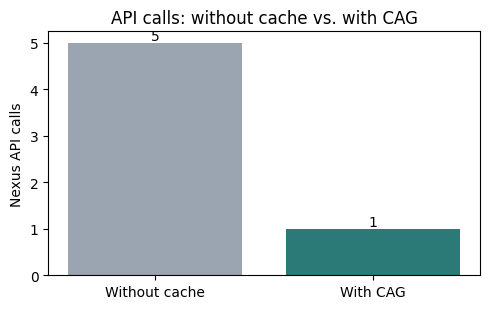

CAG saved 4 API call(s) in this run.

=== Test summary (Cell 17) ===
PASS=20  FAIL=0  SKIPPED=0  (SKIPPED tests did not run)


In [ ]:
# ---- Cell 18: final results ----
import matplotlib.pyplot as plt
RUN_CAG_DEMO = True

demo_state = STATE if STATE.index is not None else (test_state if test_state.index is not None else None)

print("=== Document and index statistics ===")
if demo_state is not None:
    print("Documents:", len(demo_state.docs), "| Chunks:", len(demo_state.chunks), "| Vectors:", demo_state.index.ntotal)
    print("Fingerprint:", demo_state.fingerprint)
else:
    print("No processed documents available.")

print("\n=== Nexus API usage (from real responses) ===")
st = client.stats
print("Model:", ACTIVE_MODEL, "| successful calls:", st["calls_ok"], "| attempts:", st["attempts"], "| retries:", st["retries"])
print("Tokens reported - prompt:", st["prompt_tokens"], "completion:", st["completion_tokens"], "total:", st["total_tokens"])
print("Rate-limit headers returned by the API:", client.last_rate_headers or "none")

if RUN_CAG_DEMO and demo_state is not None and API_READY:
    print("\n=== Live CAG demonstration: same question asked 5 times ===")
    demo_cache = ensure_cache(demo_state); demo_cache.clear()
    demo_question = "Give a one-sentence description of the main topic of these notes."
    for i in range(1, 6):
        r = answer_question(demo_state, demo_question)
        if r["error"]:
            print(f"  Ask #{i}: ERROR -> {r['error']}"); break
        print(f"  Ask #{i}: cache {r['status']:4s} | API called: {str(r['api_called']):5s} | {r['latency']:.2f}s | {r['answer'][:70]}...")
elif RUN_CAG_DEMO:
    print("\nCAG demo skipped (needs processed documents and a working Nexus connection).")

if demo_state is not None and ensure_cache(demo_state).stats["hits"] + ensure_cache(demo_state).stats["misses"] > 0:
    s = ensure_cache(demo_state).snapshot()
    print("\n=== CAG statistics ===")
    for k, v in s.items(): print(f"  {k}: {v}")
    without_cache = s["hits"] + s["api_calls_made"]
    plt.figure(figsize=(5, 3.2))
    bars = plt.bar(["Without cache", "With CAG"], [without_cache, s["api_calls_made"]], color=["#9aa5b1", "#2b7a78"])
    plt.bar_label(bars); plt.ylabel("Nexus API calls"); plt.title("API calls: without cache vs. with CAG")
    plt.tight_layout(); plt.show()
    print(f"CAG saved {s['calls_saved']} API call(s) in this run.")

print("\n=== Test summary (Cell 17) ===")
if TEST_RESULTS:
    c = collections.Counter(r["status"] for r in TEST_RESULTS)
    print(f"PASS={c['PASS']}  FAIL={c['FAIL']}  SKIPPED={c['SKIPPED']}  (SKIPPED tests did not run)")
else:
    print("Run Cell 17 first.")

## Cell 19 – Download Project Files and Supporting ZIP

**Simple explanation:** This last cell
1. prints the **screenshot capture guide** for the 8 figures (also saved as `SCREENSHOT_GUIDE.md`),
2. draws the **5 diagrams** (architecture, workflow, RAG, CAG, document processing) with `matplotlib`,
3. writes the README and `requirements.txt`,
4. adds your **real** screenshots from the `implementation_screenshots` folder (it never creates screenshots itself),
5. saves the notebook, `test_results.json` (if you ran Cell 17) and everything else into **`AI_Notes_Summarizer_RAG_CAG.zip`** and downloads it.

**Screenshot capture guide (short version)**
| Figure | What to capture |
|---|---|
| 10.1 | Application home page (Cell 16 title + tabs) |
| 10.2 | Upload tab with a PDF and a TXT file chosen |
| 10.3 | Processing status, document table and extracted text |
| 10.4 | Short Summary and Detailed Summary output |
| 10.5 | Question, answer and retrieved context (RAG) |
| 10.6 | Cache MISS then the same question as Cache HIT (CAG) |
| 10.7 | Source file + page numbers and the API Status tab |
| 10.8 | Final answer with cache statistics / Cell 18 results |

The full table with file names is printed by the cell. Hide anything private before capturing.

**Expected output:** the guide, the number of screenshots found (0 to 8) with a list of missing ones, the list of files inside the ZIP, and a browser download of the ZIP.

In [ ]:
# ---- Cell 19: diagrams, screenshot guide, README and ZIP ----
import zipfile, shutil, json, os

PACKAGE_DIR = "AI_Notes_Summarizer_RAG_CAG_package"
ZIP_NAME = "AI_Notes_Summarizer_RAG_CAG.zip"
NOTEBOOK_NAME = "AI_Notes_Summarizer_RAG_CAG.ipynb"
SCREENSHOT_DIR = "implementation_screenshots"
UPLOAD_SCREENSHOTS_NOW = False      # set True after you captured your 8 screenshots, then run this cell

EXPECTED_SCREENSHOTS = [
    "Figure_10_1_Application_Home_Page.png", "Figure_10_2_Document_Upload.png",
    "Figure_10_3_Processing_and_Extraction.png", "Figure_10_4_Summaries.png",
    "Figure_10_5_RAG_Answer.png", "Figure_10_6_CAG_Miss_and_Hit.png",
    "Figure_10_7_Sources_and_API_Status.png", "Figure_10_8_Final_Output.png"]

README_TEXT = r"""# AI Powered Notes Summarizer and Question Answering System (RAG + CAG)

Seventh Semester Final Year Capstone Project – Google Colab implementation.

## What it does
Upload PDF/TXT notes, get AI summaries, and ask questions answered **only from your notes**.
- **RAG**: Sentence Transformers embeddings + FAISS similarity search -> relevant chunks -> Navigate Labs **Nexus API**.
- **CAG**: repeated questions are answered from a cache (no API call). The cache is tied to a document fingerprint, so changed documents never return old answers.
- **Gradio** interface runs inside Colab.
- **Nexus API is the only LLM provider.** No other LLM service is used, and there is no silent fallback.

## How to run in Google Colab
1. Open https://colab.research.google.com -> **File -> Upload notebook** -> choose `AI_Notes_Summarizer_RAG_CAG.ipynb`.
2. Click the key icon (Secrets) on the left, add a secret named `NEXUS_API_KEY` with your college key, and switch **Notebook access** ON. (If you skip this, Cell 4 asks for the key in a hidden box.)
3. Run the cells from top to bottom (`Runtime -> Run all` also works). In Cell 5 choose a model from the list your key can use.
4. Cell 16 shows the interface. Cell 17 runs the 20 tests. Cell 18 shows the final statistics and the CAG demo.
5. After capturing your 8 screenshots (see `SCREENSHOT_GUIDE.md`), run Cell 19 to build the ZIP.

## Files in this package
| File / folder | Purpose |
|---|---|
| `AI_Notes_Summarizer_RAG_CAG.ipynb` | The complete notebook (19 cells) |
| `README.md` | This file |
| `SCREENSHOT_GUIDE.md` | How to take the 8 genuine screenshots |
| `requirements.txt` | Libraries used (installed by Cell 2) |
| `diagrams/` | 5 architecture / workflow diagrams (PNG) |
| `implementation_screenshots/` | Put your 8 real screenshots here |
| `test_results.json` | Written by Cell 17 when you run it (not included until you run the tests) |

## Important notes
- **API limits are never invented.** Public Nexus documentation (rate limits, token limits, model list) was not available when this project was built. The notebook reads the model list from the API, records any rate-limit headers the API sends, handles 429/timeout/auth/server errors with limited retries and exponential backoff (respecting `Retry-After`), and lets you enter RPM/TPM limits **only if your college provides them** (Cell 3).
- `MAX_CONTEXT_CHARS` and `SUMMARY_BATCH_CHARS` are the project's own safety budgets, not Nexus limits.
- Scanned (image-only) PDFs are rejected because this project does not include OCR.
- Test results are only valid when you run Cell 17 yourself with your API key. Tests that cannot run are shown as SKIPPED, never as passed.
- The API key is never stored in the notebook or printed.
"""
SCREENSHOT_GUIDE = r"""# Screenshot Capture Guide (8 genuine screenshots)

All screenshots must be taken from **your own running notebook**. Do not edit, mock up or download images.
Save them in `implementation_screenshots/` using the file names below.
**Before every screenshot:** make sure the API key is not visible (Cell 4 uses a hidden box and never prints it; do not screenshot Colab Secrets).

Suggested test files: one PDF and one TXT of your own notes (or the sample files from `CREATE_SAMPLE_FILES = True` in Cell 6).

| Figure | File name | What to show | How to get it |
|---|---|---|---|
| 10.1 | `Figure_10_1_Application_Home_Page.png` | Home page / project interface | Run Cell 16. Capture the title area and the tabs before uploading anything. |
| 10.2 | `Figure_10_2_Document_Upload.png` | Upload showing PDF and TXT files | Tab "1 Upload & Process": select one PDF and one TXT so both names show in the upload box. |
| 10.3 | `Figure_10_3_Processing_and_Extraction.png` | Processing status + extracted text | Press **Process Documents**. Capture the status, the document table and the extracted text preview. |
| 10.4 | `Figure_10_4_Summaries.png` | Short and Detailed summaries | Tab "2 Summaries": generate *Short Summary*, then *Detailed Summary* (scroll so both are visible, or take one screenshot per type and place them side by side in your report). |
| 10.5 | `Figure_10_5_RAG_Answer.png` | Question, answer, retrieved context | Tab "3 Ask Questions": ask a question about your notes. Capture the answer, sources and retrieved context. |
| 10.6 | `Figure_10_6_CAG_Miss_and_Hit.png` | Cache MISS then Cache HIT | Ask a NEW question (shows MISS) and capture; ask the same question again (shows HIT, 0 API calls) and capture both, or use Cell 18's live demo output. |
| 10.7 | `Figure_10_7_Sources_and_API_Status.png` | Source file + page, API usage/status | Capture the source list under an answer plus the "4 API Status" tab (calls, tokens, retries, rate-limit headers). |
| 10.8 | `Figure_10_8_Final_Output.png` | Final answer and project results | Capture a completed answer together with the cache statistics, or the Cell 18 final results and chart. |

Tips: use the browser zoom (Ctrl +/-) so text is readable; Windows `Win+Shift+S`, macOS `Cmd+Shift+4`.

**Adding them to the ZIP:** put the PNG files into the Colab folder `implementation_screenshots/` (left file panel) or set `UPLOAD_SCREENSHOTS_NOW = True` in Cell 19 and select them. Cell 19 lists which of the 8 are missing.
"""
REQUIREMENTS = """pymupdf
faiss-cpu
sentence-transformers
gradio
requests
numpy
matplotlib
"""

import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Rectangle

PALETTE = {"user": "#dbeafe", "local": "#e0f2f1", "store": "#fef3c7", "api": "#fde2e4", "cache": "#ede9fe", "note": "#f3f4f6"}

def draw_diagram(path, title, nodes, edges, size=(14, 7), subtitle=""):
    """nodes: {id: (x, y, text, kind)}; edges: [(from_id, to_id, label)]. Boxes are drawn on a 0-14 x 0-8 grid."""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 14); ax.set_ylim(-0.4, 8); ax.axis("off")
    ax.text(7, 7.7, title, ha="center", va="center", fontsize=16, fontweight="bold")
    if subtitle:
        ax.text(7, 7.3, subtitle, ha="center", va="center", fontsize=10, color="#444")
    patches = {}
    for nid, (x, y, text, kind) in nodes.items():
        w = 2.5 if "\n" in text or len(text) > 16 else 2.2
        box = FancyBboxPatch((x - w / 2, y - 0.5), w, 1.0, boxstyle="round,pad=0.05,rounding_size=0.15",
                             fc=PALETTE[kind], ec="#334155", lw=1.4, zorder=2)
        ax.add_patch(box); patches[nid] = box
        ax.text(x, y, text, ha="center", va="center", fontsize=9.5, zorder=3)
    for edge in edges:
        src, dst, label = edge[:3]
        frac = edge[3] if len(edge) > 3 else 0.5
        arrow = FancyArrowPatch(posA=nodes[src][:2], posB=nodes[dst][:2], patchA=patches[src], patchB=patches[dst],
                                arrowstyle="-|>", mutation_scale=16, lw=1.5, color="#1f2937", zorder=1,
                                shrinkA=2, shrinkB=2, connectionstyle="arc3,rad=0.0")
        ax.add_patch(arrow)
        if label:
            mx = nodes[src][0] + (nodes[dst][0] - nodes[src][0]) * frac; my = nodes[src][1] + (nodes[dst][1] - nodes[src][1]) * frac
            ax.text(mx, my + 0.18, label, ha="center", va="bottom", fontsize=8.5, color="#7c2d12",
                    bbox=dict(fc="white", ec="none", pad=0.6, alpha=0.9), zorder=4)
    legend = [("Student / interface", "user"), ("Runs in Colab", "local"), ("Stored data", "store"), ("Cache (CAG)", "cache"), ("Nexus API (only LLM)", "api")]
    for i, (name, kind) in enumerate(legend):
        ax.add_patch(Rectangle((0.4 + i * 2.7, -0.3), 0.35, 0.3, fc=PALETTE[kind], ec="#334155", lw=1))
        ax.text(0.85 + i * 2.7, -0.15, name, va="center", fontsize=8)
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white"); plt.close(fig)

def draw_all_diagrams(out_dir):
    os.makedirs(out_dir, exist_ok=True)
    made = []
    # 1. overall architecture
    draw_diagram(os.path.join(out_dir, "1_system_architecture.png"), "Overall System Architecture",
        {"load": (1.8, 6.2, "Document loader\nPyMuPDF / TXT", "local"),
         "proc": (4.6, 6.2, "Clean + chunk text\n(page metadata kept)", "local"),
         "emb": (7.4, 6.2, "Sentence Transformers\n(local embeddings)", "local"),
         "faiss": (10.6, 6.2, "FAISS vector index\n+ fingerprint", "store"),
         "ui": (1.8, 3.6, "Student\nGradio interface\n(inside Colab)", "user"),
         "cag": (4.5, 3.6, "CAG answer cache\n(hit / miss)", "cache"),
         "rag": (7.4, 3.6, "RAG retriever\n(top-k similarity)", "local"),
         "nexus": (12.7, 3.6, "Nexus API\nnexusapi.navigatelabs.ai\n(only LLM provider)", "api"),
         "sum": (10.6, 1.4, "Notes summariser\n(reads document text)", "local")},
        [("ui", "load", "upload"), ("load", "proc", ""), ("proc", "emb", ""), ("emb", "faiss", ""),
         ("ui", "cag", "question"), ("cag", "rag", "miss"), ("faiss", "rag", "search"),
         ("rag", "nexus", "context + question", 0.3), ("sum", "nexus", "notes"), ("faiss", "sum", "")],
        subtitle="Everything except the LLM call runs inside the Colab notebook")
    made.append("1_system_architecture.png")
    # 2. workflow
    draw_diagram(os.path.join(out_dir, "2_application_workflow.png"), "Application Workflow",
        {"up": (1.5, 6.0, "1. Upload\nPDF / TXT", "user"), "val": (4.3, 6.0, "2. Validate\n(type, empty, duplicate)", "local"),
         "ext": (7.1, 6.0, "3. Extract text\n(+ page numbers)", "local"), "cln": (9.9, 6.0, "4. Clean text", "local"),
         "chk": (12.5, 6.0, "5. Chunk\n(size + overlap)", "local"),
         "emb": (12.5, 4.2, "6. Embed chunks", "local"), "idx": (9.9, 4.2, "7. FAISS index", "store"),
         "ask": (6.5, 4.2, "8a. Ask a question\n(RAG + CAG)", "user"), "sm": (6.5, 2.4, "8b. Generate summary\n(Nexus API)", "user"),
         "out": (2.6, 3.3, "9. Show answer / summary\n+ source + page + cache status", "user")},
        [("up", "val", ""), ("val", "ext", ""), ("ext", "cln", ""), ("cln", "chk", ""), ("chk", "emb", ""), ("emb", "idx", ""),
         ("idx", "ask", ""), ("idx", "sm", ""), ("ask", "out", ""), ("sm", "out", "")])
    made.append("2_application_workflow.png")
    # 3. RAG
    draw_diagram(os.path.join(out_dir, "3_rag_pipeline.png"), "RAG Pipeline",
        {"q": (1.6, 5.6, "Student question", "user"), "qe": (4.6, 5.6, "Question embedding\n(Sentence Transformers)", "local"),
         "fs": (7.8, 5.6, "FAISS similarity search\n(top-k chunks)", "store"), "flt": (11.2, 5.6, "Keep chunks above\nMIN_SIMILARITY", "local"),
         "ctx": (8.6, 3.3, "Build context\n[S1] file + page ...", "local"), "llm": (5.2, 3.3, "Nexus chat completion\n'answer only from context'", "api"),
         "ans": (1.9, 3.3, "Answer + source file\n+ page number", "user"),
         "nf": (12.2, 3.0, "Nothing relevant:\n'The answer was not found\nin the uploaded documents.'", "note")},
        [("q", "qe", ""), ("qe", "fs", ""), ("fs", "flt", ""), ("flt", "ctx", "relevant"), ("ctx", "llm", ""), ("llm", "ans", ""), ("flt", "nf", "none")],
        subtitle="Only the retrieved chunks (not the whole document) are sent to the Nexus API")
    made.append("3_rag_pipeline.png")
    # 4. CAG
    draw_diagram(os.path.join(out_dir, "4_cag_cache_workflow.png"), "CAG Cache Workflow",
        {"q": (1.6, 6.0, "Student question", "user"), "norm": (4.6, 6.0, "Normalise question\n(lower-case, spaces)", "local"),
         "key": (7.8, 6.0, "Cache key = question +\nfingerprint + model + settings", "cache"), "look": (11.2, 6.0, "Entry found?", "cache"),
         "ver": (11.2, 4.1, "Retrieve locally and compare\ncontext hash (no API)", "local"), "hit": (11.2, 2.2, "Cache HIT\nreturn cached answer\n0 API calls", "cache"),
         "rag": (6.2, 3.3, "Cache MISS\nRAG retrieval", "local"), "api": (3.0, 2.2, "Nexus API\ngenerate answer", "api"),
         "store": (6.2, 1.2, "Store answer in cache\n(never store errors)", "cache")},
        [("q", "norm", ""), ("norm", "key", ""), ("key", "look", ""), ("look", "ver", "yes"), ("ver", "hit", "same"), ("look", "rag", "no"),
         ("ver", "rag", "changed: discard"), ("rag", "api", ""), ("api", "store", ""), ("store", "hit", "next time")],
        subtitle="A new document set changes the fingerprint, so old answers are deleted and can never be returned")
    made.append("4_cag_cache_workflow.png")
    # 5. document processing
    draw_diagram(os.path.join(out_dir, "5_document_processing.png"), "Document Processing",
        {"f": (1.6, 5.8, "PDF / TXT files\n(one or many)", "user"), "chk": (4.6, 5.8, "Checks: type, empty,\nduplicate (SHA-256)", "local"),
         "ext": (7.8, 5.8, "PyMuPDF (PDF pages)\nTXT decode", "local"), "cl": (11.2, 5.8, "Clean: Unicode, hyphens,\nspaces, page markers", "local"),
         "sp": (11.2, 3.6, "Split into sentences\npack into chunks", "local"), "md": (7.8, 3.6, "Metadata per chunk:\nfile, page, chunk no.", "store"),
         "em": (4.6, 3.6, "Embeddings\n(Sentence Transformers)", "local"), "fa": (4.6, 1.6, "FAISS index +\ndocument fingerprint", "store"),
         "rej": (1.6, 3.6, "Rejected files\nwith a reason", "note")},
        [("f", "chk", ""), ("chk", "ext", "ok"), ("chk", "rej", "bad"), ("ext", "cl", ""), ("cl", "sp", ""), ("sp", "md", ""), ("md", "em", ""), ("em", "fa", "")])
    made.append("5_document_processing.png")
    return made

# ---------- screenshot guide (printed here and saved in the ZIP) ----------
print(SCREENSHOT_GUIDE)
os.makedirs(SCREENSHOT_DIR, exist_ok=True)

if UPLOAD_SCREENSHOTS_NOW:
    try:
        from google.colab import files
        for fname, content in files.upload().items():
            if fname.lower().endswith((".png", ".jpg", ".jpeg")):
                with open(os.path.join(SCREENSHOT_DIR, fname), "wb") as f: f.write(content)
                print("Saved screenshot:", fname)
            else:
                print("Ignored (not an image):", fname)
    except ImportError:
        print("Upload box only works in Google Colab.")

present = sorted(f for f in os.listdir(SCREENSHOT_DIR) if f.lower().endswith((".png", ".jpg", ".jpeg")))
print(f"\nScreenshots found in {SCREENSHOT_DIR}/: {len(present)} of 8")
missing = [n for n in EXPECTED_SCREENSHOTS if n not in present]
if missing:
    print("Not found yet (take them from your running app, see the guide above):")
    for n in missing: print("  -", n)

# ---------- build the package folder ----------
if os.path.isdir(PACKAGE_DIR): shutil.rmtree(PACKAGE_DIR)
os.makedirs(os.path.join(PACKAGE_DIR, "diagrams")); os.makedirs(os.path.join(PACKAGE_DIR, SCREENSHOT_DIR))
for name, text in [("README.md", README_TEXT), ("SCREENSHOT_GUIDE.md", SCREENSHOT_GUIDE), ("requirements.txt", REQUIREMENTS)]:
    with open(os.path.join(PACKAGE_DIR, name), "w", encoding="utf-8") as f: f.write(text)
draw_all_diagrams(os.path.join(PACKAGE_DIR, "diagrams"))
for fname in present:
    shutil.copy(os.path.join(SCREENSHOT_DIR, fname), os.path.join(PACKAGE_DIR, SCREENSHOT_DIR, fname))
if not present:
    with open(os.path.join(PACKAGE_DIR, SCREENSHOT_DIR, "PUT_YOUR_REAL_SCREENSHOTS_HERE.txt"), "w") as f:
        f.write("Add the 8 screenshots captured from your running notebook. See SCREENSHOT_GUIDE.md.\n")
if os.path.exists("test_results.json"):
    shutil.copy("test_results.json", PACKAGE_DIR)       # only exists if you ran Cell 17

# ---------- the notebook itself (works in Colab; otherwise add it by hand) ----------
nb_saved = False
try:
    from google.colab import _message
    notebook_json = _message.blocking_request("get_ipynb", timeout_sec=60)["ipynb"]
    with open(os.path.join(PACKAGE_DIR, NOTEBOOK_NAME), "w", encoding="utf-8") as f: json.dump(notebook_json, f)
    nb_saved = True
except Exception:
    for candidate in (NOTEBOOK_NAME, "/content/" + NOTEBOOK_NAME):
        if os.path.exists(candidate):
            shutil.copy(candidate, os.path.join(PACKAGE_DIR, NOTEBOOK_NAME)); nb_saved = True; break
if not nb_saved:
    print("\nCould not add the notebook automatically. Use File -> Download -> Download .ipynb and put it in the ZIP yourself.")

# ---------- zip ----------
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for folder, _, names in os.walk(PACKAGE_DIR):
        for n in names:
            full = os.path.join(folder, n); z.write(full, os.path.relpath(full, PACKAGE_DIR))
print(f"\nZIP created: {ZIP_NAME}")
with zipfile.ZipFile(ZIP_NAME) as z:
    for info in z.infolist(): print(f"  {info.filename}  ({info.file_size} bytes)")

try:
    from google.colab import files
    files.download(ZIP_NAME)
except ImportError:
    print("Not in Colab: the ZIP is saved in the current folder.")

# Screenshot Capture Guide (8 genuine screenshots)

All screenshots must be taken from **your own running notebook**. Do not edit, mock up or download images.
Save them in `implementation_screenshots/` using the file names below.
**Before every screenshot:** make sure the API key is not visible (Cell 4 uses a hidden box and never prints it; do not screenshot Colab Secrets).

Suggested test files: one PDF and one TXT of your own notes (or the sample files from `CREATE_SAMPLE_FILES = True` in Cell 6).

| Figure | File name | What to show | How to get it |
|---|---|---|---|
| 10.1 | `Figure_10_1_Application_Home_Page.png` | Home page / project interface | Run Cell 16. Capture the title area and the tabs before uploading anything. |
| 10.2 | `Figure_10_2_Document_Upload.png` | Upload showing PDF and TXT files | Tab "1 Upload & Process": select one PDF and one TXT so both names show in the upload box. |
| 10.3 | `Figure_10_3_Processing_and_Extraction.png` | Processing status + extracted tex

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>